# Trực quan hóa dữ liệu lưu lượng mạng nhằm phát hiện và phân tích các dạng tấn công mạng

**Học phần:** Trực quan hóa dữ liệu &nbsp;|&nbsp; **Bộ dữ liệu:** UNSW-NB15 (training-set 175.341 luồng, testing-set 82.332 luồng)

## Câu chuyện của báo cáo

Một quản trị viên mạng nhìn vào 175 nghìn luồng kết nối. **Chỉ bằng biểu đồ, có thể nhận ra luồng nào là tấn công, và mỗi kiểu tấn công "trông" khác nhau thế nào không?**

Notebook đi theo 8 câu hỏi, mỗi câu hỏi gắn với một nhóm biểu đồ của học phần:

| # | Câu hỏi phân tích | Biểu đồ sử dụng | Chương |
|---|---|---|---|
| Q1 | Dữ liệu có bao nhiêu tấn công, gồm những loại nào? | Donut, bar ngang, Pareto, grouped bar | 3, 4 |
| Q2 | Tấn công đi qua giao thức / dịch vụ / trạng thái nào? | 100% stacked bar, heatmap, WordCloud | 4, 5.3, 5.4 |
| Q3 | Dấu hiệu định lượng nào phân biệt tấn công với bình thường? | Histogram, boxplot, violin, ridgeline, hexbin, ECDF | 3, 4, 5.1 |
| Q4 | "Chân dung" của từng loại tấn công? | Spider chart, clustermap, parallel coordinates | 5.2, 5.3 |
| Q5 | Các đặc trưng liên quan với nhau ra sao? | Heatmap tương quan, lollipop | 5.3, 4 |
| Q6 | Cấu trúc phân cấp, mạng và luồng của lưu lượng? | Treemap, sunburst, Sankey, network graph | 6 |
| Q7 | Trong không gian ít chiều, các loại tấn công có tách nhau? | PCA, t-SNE scatter | 3 |
| Q8 | Từ quan sát trực quan đến phát hiện tự động | Luật 1 đặc trưng, ROC, confusion matrix, feature importance | 5.3, 9 |

Phần Dashboard (chương 8) nằm ở file `app.py` (Streamlit). Phần kết là tóm tắt kể chuyện bằng dữ liệu (chương 9).

## 0. Chuẩn bị

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import networkx as nx
from scipy.stats import gaussian_kde
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False})

os.makedirs('figures', exist_ok=True)

def save(name):
    """Lưu hình vào thư mục figures/ để chèn vào slide báo cáo."""
    plt.savefig(f'figures/{name}.png', dpi=200, bbox_inches='tight')

**Nguyên tắc thiết kế dùng xuyên suốt (chương 2):** mỗi loại tấn công giữ **một màu cố định** trên mọi biểu đồ; `Normal` luôn là màu xám để tấn công nổi lên; thứ tự các loại luôn giống nhau; các đại lượng lệch mạnh được vẽ trên thang log.

In [2]:
# Thứ tự và màu cố định cho từng loại lưu lượng
ORDER = ['Normal', 'Generic', 'Exploits', 'Fuzzers', 'DoS', 'Reconnaissance',
         'Analysis', 'Backdoor', 'Shellcode', 'Worms']
ATTACKS = ORDER[1:]
PALETTE = {'Normal': '#9AA0A6', 'Generic': '#D62728', 'Exploits': '#FF7F0E', 'Fuzzers': '#1F77B4',
           'DoS': '#9467BD', 'Reconnaissance': '#2CA02C', 'Analysis': '#8C564B', 'Backdoor': '#E377C2',
           'Shellcode': '#17BECF', 'Worms': '#BCBD22'}
BIN_PALETTE = {'Normal': '#9AA0A6', 'Attack': '#D62728'}

def rgba(hex_color, alpha):
    h = hex_color.lstrip('#')
    return f'rgba({int(h[0:2], 16)},{int(h[2:4], 16)},{int(h[4:6], 16)},{alpha})'

### Đọc dữ liệu

> ⚠️ **Đọc từ file CSV gốc, không đọc từ Google Sheets.** Bản Google Sheets (ngôn ngữ Việt Nam) đã hiểu dấu chấm thập phân thành dấu phân cách hàng nghìn, nên các cột số thực bị sai (ví dụ `dur = 0.121478` thành `121478`).

In [3]:
# Nếu dùng Colab và để dữ liệu trên Drive thì bỏ comment 2 dòng dưới
# from google.colab import drive
# drive.mount('/content/drive')

DATA_DIRS = ['.', 'data', '/content/unsw_project', '/content', '/content/drive/MyDrive',
             '/content/drive/MyDrive/unsw_project']

def find_file(name):
    for d in DATA_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Không thấy {name}. Hãy thêm thư mục chứa file vào DATA_DIRS.')

train_raw = pd.read_csv(find_file('UNSW_NB15_training-set.csv'))
test_raw = pd.read_csv(find_file('UNSW_NB15_testing-set.csv'))
print('train:', train_raw.shape, '| test:', test_raw.shape)
# File tải lên Colab chưa xong sẽ bị cụt dòng -> kiểm tra ngay để không vẽ trên dữ liệu thiếu
assert len(train_raw) == 175341 and len(test_raw) == 82332 and train_raw['label'].notna().all(), (
    'File CSV chưa tải lên đầy đủ (train phải có 175.341 dòng, test 82.332 dòng). '
    'Hãy xóa file trên Colab, tải lại, đợi tải xong 100% rồi chạy lại.')
train_raw.head()

train: (175341, 45) | test: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 1. Hiểu và tiền xử lý dữ liệu

Mỗi dòng là **một luồng kết nối** (flow). 45 cột chia thành các nhóm:

| Nhóm | Cột tiêu biểu | Ý nghĩa |
|---|---|---|
| Định danh luồng | `proto`, `service`, `state` | giao thức, dịch vụ tầng ứng dụng, trạng thái kết nối |
| Khối lượng | `spkts`, `dpkts`, `sbytes`, `dbytes`, `smean`, `dmean` | số gói / số byte / kích thước gói trung bình theo chiều nguồn → đích và ngược lại |
| Thời gian & tốc độ | `dur`, `rate`, `sload`, `dload`, `sinpkt`, `dinpkt`, `sjit`, `djit` | thời lượng, tốc độ, khoảng cách giữa các gói, jitter |
| TCP | `sttl`, `dttl`, `swin`, `dwin`, `tcprtt`, `synack`, `ackdat` | TTL, cửa sổ TCP, thời gian bắt tay |
| Đếm ngữ cảnh | `ct_srv_src`, `ct_dst_src_ltm`, `ct_state_ttl`, ... | số kết nối cùng dịch vụ / cùng địa chỉ trong 100 kết nối gần nhất |
| Nhãn | `attack_cat`, `label` | loại tấn công (10 lớp) và nhãn nhị phân |

In [4]:
# Kiểm tra chất lượng: thiếu, trùng, giá trị "-" ẩn
quality = pd.DataFrame({
    'kiểu': train_raw.dtypes.astype(str),
    'số giá trị khác nhau': train_raw.nunique(),
    'NaN': train_raw.isna().sum(),
    'giá trị "-"': (train_raw == '-').sum(),
})
print('Số dòng trùng nhau hoàn toàn (bỏ id):', train_raw.drop(columns='id').duplicated().sum())
quality[(quality['NaN'] > 0) | (quality['giá trị "-"'] > 0) | (quality['kiểu'].isin(['object', 'str', 'string']))]

Số dòng trùng nhau hoàn toàn (bỏ id): 67601


,kiểu,số giá trị khác nhau,NaN,"giá trị ""-"""
proto,object,133,0,0
service,object,13,0,94168
state,object,9,0,0
attack_cat,object,10,0,0


**Nhận xét.**
- Có **67.601 dòng trùng nhau hoàn toàn (38,6%)**, trong đó 35.819 dòng là Generic. Không xóa, vì mỗi dòng là một luồng có thật: việc hàng chục nghìn luồng giống hệt nhau chính là dấu vết của tấn công tự động (xem Q4).
- `isnull()` báo không thiếu, nhưng cột `service` có hơn một nửa số dòng mang giá trị `"-"` (dịch vụ không xác định được). Không xóa và không thay bằng mode, vì "không rõ dịch vụ" bản thân nó là thông tin; ta đặt thành nhãn `unknown`.

Khác với bản cũ, ở đây **không LabelEncode trước khi vẽ**: biểu đồ cần tên thật (`dns`, `Exploits`) chứ không phải con số 1, 3, 6. Việc mã hóa chỉ làm ở bước mô hình (Q8).

In [5]:
CAT_COLS = ['proto', 'service', 'state']
NUM_COLS = [c for c in train_raw.columns if c not in CAT_COLS + ['id', 'attack_cat', 'label']]
TOP_PROTO = ['tcp', 'udp', 'unas', 'arp', 'ospf', 'sctp']

def clean(df):
    df = df.drop(columns='id').copy()
    for c in CAT_COLS + ['attack_cat']:
        df[c] = df[c].astype(str).str.strip()
    df['service'] = df['service'].replace('-', 'unknown')
    df['attack_cat'] = pd.Categorical(df['attack_cat'], categories=ORDER, ordered=True)
    df['label_name'] = np.where(df['label'] == 1, 'Attack', 'Normal')
    # 133 giao thức -> giữ 6 giao thức lớn nhất, còn lại gộp thành "giao thức hiếm"
    df['proto_grp'] = np.where(df['proto'].isin(TOP_PROTO), df['proto'], 'hiếm (khác)')
    return df

train, test = clean(train_raw), clean(test_raw)

def strat_sample(df, n_per_class, seed=42):
    """Lấy mẫu phân tầng theo loại tấn công để biểu đồ điểm không bị lớp lớn che lớp nhỏ."""
    shuffled = df.sample(frac=1, random_state=seed)
    return shuffled.groupby('attack_cat', observed=True).head(n_per_class)

print('Số đặc trưng số:', len(NUM_COLS), '| Số giao thức:', train['proto'].nunique(),
      '| Số dịch vụ:', train['service'].nunique(), '| Số trạng thái:', train['state'].nunique())

Số đặc trưng số: 39 | Số giao thức: 133 | Số dịch vụ: 13 | Số trạng thái: 9


### Vì sao phải dùng thang log?

Lưu lượng mạng có phân phối **đuôi rất dài**: đa số luồng chỉ vài trăm byte, một số ít lên tới hàng triệu byte. Vẽ thẳng thì mọi thứ dồn về một cột.

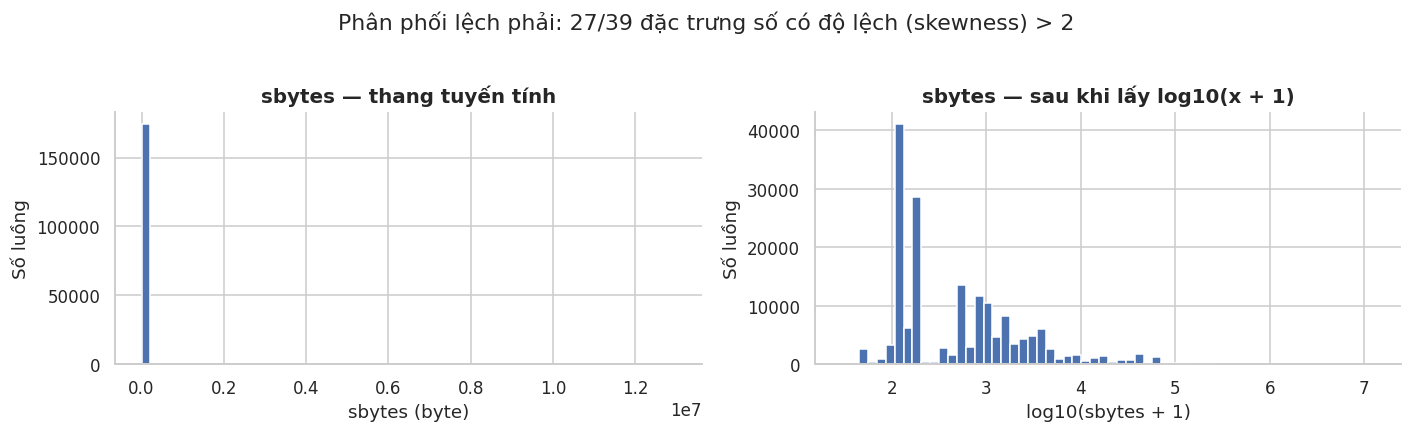

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(train['sbytes'], bins=60, color='#4C72B0')
axes[0].set(title='sbytes — thang tuyến tính', xlabel='sbytes (byte)', ylabel='Số luồng')
axes[1].hist(np.log10(train['sbytes'] + 1), bins=60, color='#4C72B0')
axes[1].set(title='sbytes — sau khi lấy log10(x + 1)', xlabel='log10(sbytes + 1)', ylabel='Số luồng')
skew = train[NUM_COLS].skew().sort_values(ascending=False)
fig.suptitle(f'Phân phối lệch phải: {int((skew > 2).sum())}/{len(NUM_COLS)} đặc trưng số có độ lệch (skewness) > 2', y=1.03)
plt.tight_layout(); save('01_log_scale'); plt.show()

# Các đặc trưng lệch mạnh sẽ được vẽ ở thang log trong toàn bộ notebook
LOG_COLS = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload',
            'sinpkt', 'dinpkt', 'sjit', 'djit', 'smean', 'dmean']
logd = train.copy()
logd[LOG_COLS] = np.log10(train[LOG_COLS] + 1)

## Q1. Dữ liệu có bao nhiêu tấn công, gồm những loại nào?

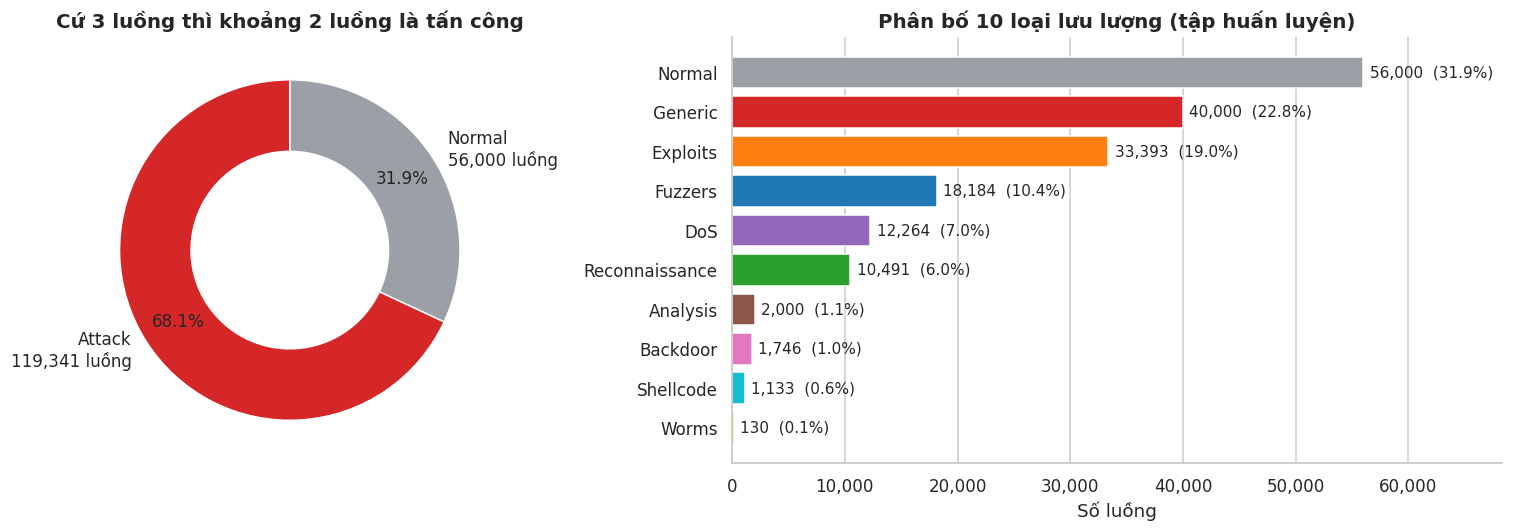

In [7]:
counts = train['attack_cat'].value_counts().reindex(ORDER)
share = counts / counts.sum() * 100
bin_counts = train['label_name'].value_counts().reindex(['Normal', 'Attack'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.8]})

# Donut: tỉ lệ nhị phân
axes[0].pie(bin_counts, labels=[f'{k}\n{v:,} luồng' for k, v in bin_counts.items()],
            colors=[BIN_PALETTE[k] for k in bin_counts.index], startangle=90, counterclock=False,
            autopct='%1.1f%%', pctdistance=0.78, wedgeprops=dict(width=0.42, edgecolor='white'),
            textprops={'fontsize': 11})
axes[0].set_title('Cứ 3 luồng thì khoảng 2 luồng là tấn công')

# Bar ngang đã sắp xếp: phân bố 10 lớp
s = counts.sort_values()
axes[1].barh(s.index.astype(str), s.values, color=[PALETTE[k] for k in s.index])
for y, (k, v) in enumerate(s.items()):
    axes[1].text(v + counts.max() * 0.01, y, f'{v:,}  ({share[k]:.1f}%)', va='center', fontsize=10)
axes[1].set(xlim=(0, counts.max() * 1.22), xlabel='Số luồng', title='Phân bố 10 loại lưu lượng (tập huấn luyện)')
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].grid(axis='y', visible=False)
plt.tight_layout(); save('02_tong_quan'); plt.show()

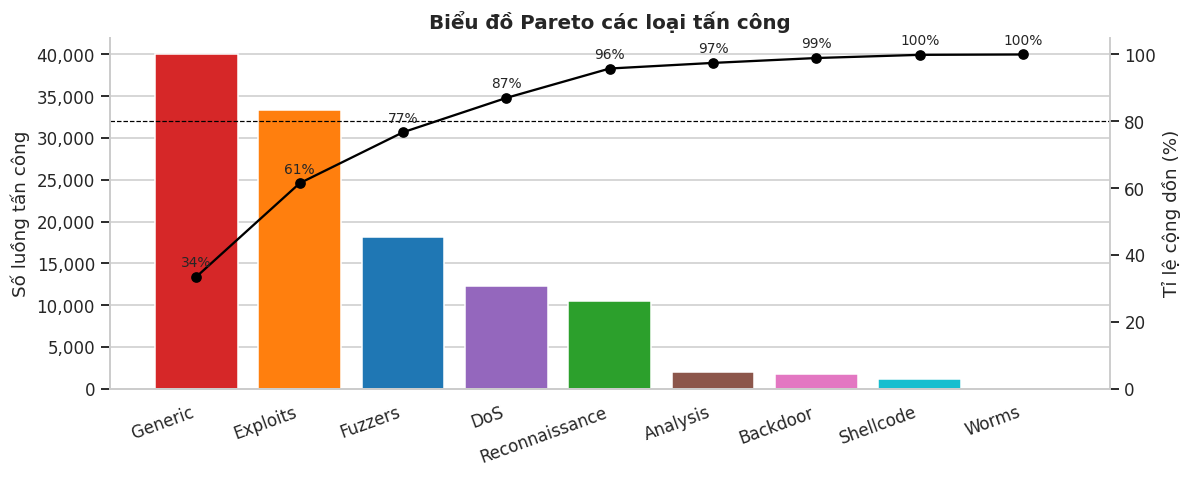

4 loại lớn nhất (Generic, Exploits, Fuzzers, DoS) chiếm 87.0% tổng số luồng tấn công.
Lớp lớn nhất gấp 308 lần lớp nhỏ nhất (Worms: 130 luồng).


In [8]:
# Pareto: những loại tấn công nào chiếm phần lớn?
att = counts[ATTACKS].sort_values(ascending=False)
cum = att.cumsum() / att.sum() * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(att.index.astype(str), att.values, color=[PALETTE[k] for k in att.index])
ax.set(ylabel='Số luồng tấn công', title='Biểu đồ Pareto các loại tấn công')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(axis='x', visible=False)
ax2 = ax.twinx()
ax2.plot(att.index.astype(str), cum.values, color='black', marker='o')
ax2.axhline(80, color='black', ls='--', lw=0.8)
ax2.set(ylim=(0, 105), ylabel='Tỉ lệ cộng dồn (%)'); ax2.grid(False); ax2.spines['right'].set_visible(True)
for x, v in enumerate(cum.values):
    ax2.text(x, v + 3, f'{v:.0f}%', ha='center', fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
plt.tight_layout(); save('03_pareto'); plt.show()

n80 = int((cum < 80).sum() + 1)
print(f'{n80} loại lớn nhất ({", ".join(att.index[:n80])}) chiếm {cum.iloc[n80 - 1]:.1f}% tổng số luồng tấn công.')
print(f'Lớp lớn nhất gấp {att.iloc[0] / att.iloc[-1]:.0f} lần lớp nhỏ nhất ({att.index[-1]}: {att.iloc[-1]} luồng).')

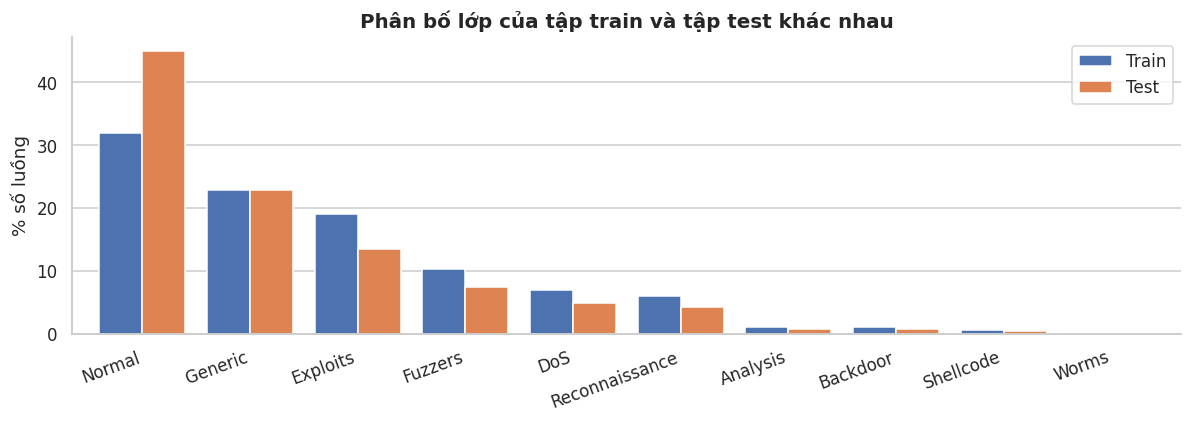

attack_cat,Normal,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
Train,31.9,22.8,19.0,10.4,7.0,6.0,1.1,1.0,0.6,0.1
Test,44.9,22.9,13.5,7.4,5.0,4.2,0.8,0.7,0.5,0.1


In [9]:
# Tập train và tập test có cùng phân bố không? (quan trọng cho Q8)
cmp = pd.DataFrame({'Train': train['attack_cat'].value_counts(normalize=True),
                    'Test': test['attack_cat'].value_counts(normalize=True)}).reindex(ORDER) * 100
ax = cmp.plot(kind='bar', figsize=(11, 4), color=['#4C72B0', '#DD8452'], width=0.8)
ax.set(ylabel='% số luồng', xlabel='', title='Phân bố lớp của tập train và tập test khác nhau')
ax.grid(axis='x', visible=False)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
plt.tight_layout(); save('04_train_vs_test'); plt.show()
cmp.round(1).T

**Nhận xét Q1.**
- Tập huấn luyện có **119.341 luồng tấn công (68,1%)** và 56.000 luồng bình thường (31,9%). Tỉ lệ này ngược với thực tế (tấn công thường rất hiếm) vì tập dữ liệu đã được chọn mẫu lại cho việc huấn luyện.
- Mất cân bằng nằm ở **bên trong nhóm tấn công**: Generic (40.000) và Exploits (33.393) áp đảo, trong khi Worms chỉ có 130 luồng, ít hơn Generic khoảng 300 lần. Vì vậy các biểu đồ về sau dùng **tỉ lệ %** hoặc **lấy mẫu phân tầng** thay vì số tuyệt đối, và ở Q8 không thể chỉ nhìn Accuracy.
- Tập test có tỉ lệ Normal cao hơn tập train, nên đánh giá mô hình phải làm trên tập test chính thức.

## Q2. Tấn công đi qua giao thức, dịch vụ, trạng thái nào?

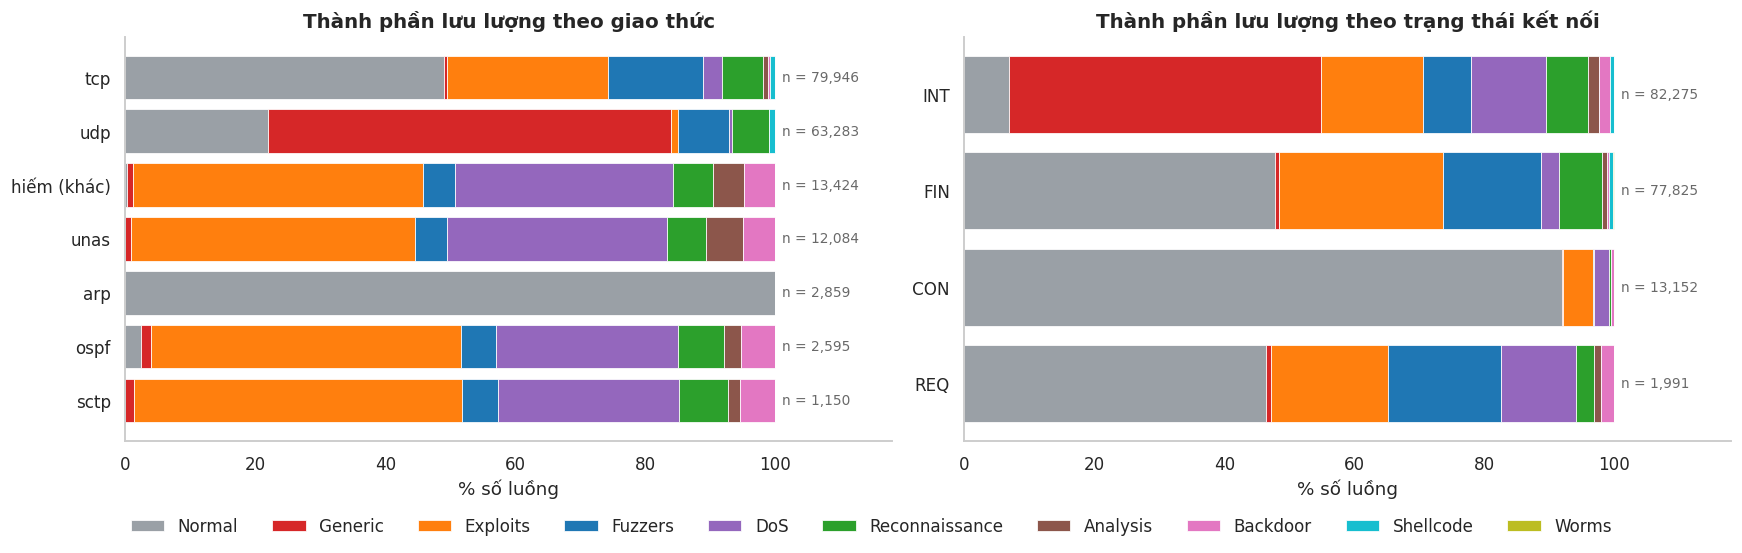

Ngoài tcp / udp / arp: 130 giao thức, 29,253 luồng, 99.7% là tấn công (chỉ 98 luồng bình thường).


In [10]:
def stacked_pct(df, row, title, ax, order_rows=None):
    """100% stacked bar: mỗi thanh là một giá trị của `row`, chia theo loại tấn công."""
    ct = pd.crosstab(df[row], df['attack_cat'])
    ct = ct.loc[order_rows] if order_rows is not None else ct.loc[ct.sum(axis=1).sort_values().index]
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    for cat in ORDER:
        ax.barh(pct.index, pct[cat], left=left, color=PALETTE[cat], label=cat, edgecolor='white', lw=0.5)
        left += pct[cat].values
    for y, n in enumerate(ct.sum(axis=1)):
        ax.text(101, y, f'n = {n:,}', va='center', fontsize=9, color='dimgray')
    ax.set(xlim=(0, 118), xlabel='% số luồng', title=title)
    ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
stacked_pct(train, 'proto_grp', 'Thành phần lưu lượng theo giao thức', axes[0])
top_state = train['state'].value_counts().index[:4]
stacked_pct(train[train['state'].isin(top_state)], 'state', 'Thành phần lưu lượng theo trạng thái kết nối', axes[1])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=10, loc='lower center', bbox_to_anchor=(0.5, -0.06), frameon=False)
plt.tight_layout(); save('05_proto_state'); plt.show()

rare = train[~train['proto'].isin(['tcp', 'udp', 'arp'])]
print(f'Ngoài tcp / udp / arp: {rare["proto"].nunique()} giao thức, {len(rare):,} luồng, '
      f'{rare["label"].mean() * 100:.1f}% là tấn công (chỉ {int((rare["label"] == 0).sum())} luồng bình thường).')

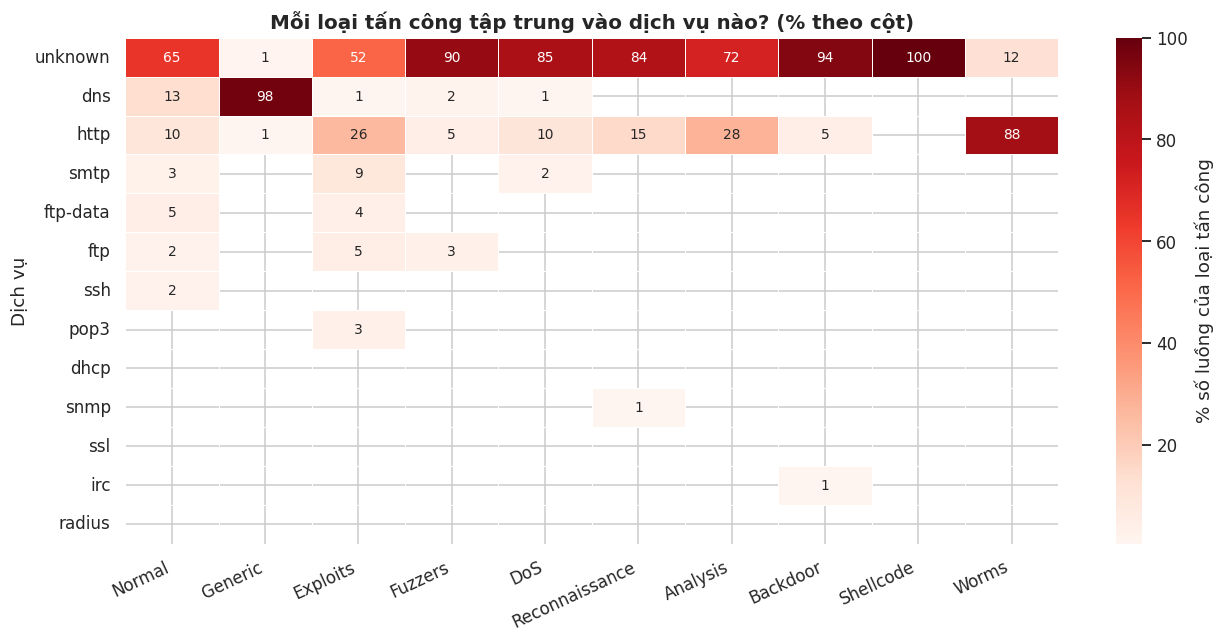

In [11]:
# Heatmap: mỗi loại tấn công dùng dịch vụ nào? (chuẩn hóa theo cột => mỗi cột cộng lại 100%)
ct = pd.crosstab(train['service'], train['attack_cat'])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
col_pct = ct.div(ct.sum(axis=0), axis=1) * 100

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(col_pct, annot=True, fmt='.0f', cmap='Reds', linewidths=0.5, linecolor='white',
            cbar_kws={'label': '% số luồng của loại tấn công'}, ax=ax,
            annot_kws={'fontsize': 9}, mask=(col_pct < 0.5))
ax.set(xlabel='', ylabel='Dịch vụ', title='Mỗi loại tấn công tập trung vào dịch vụ nào? (% theo cột)')
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.tight_layout(); save('06_heatmap_service'); plt.show()

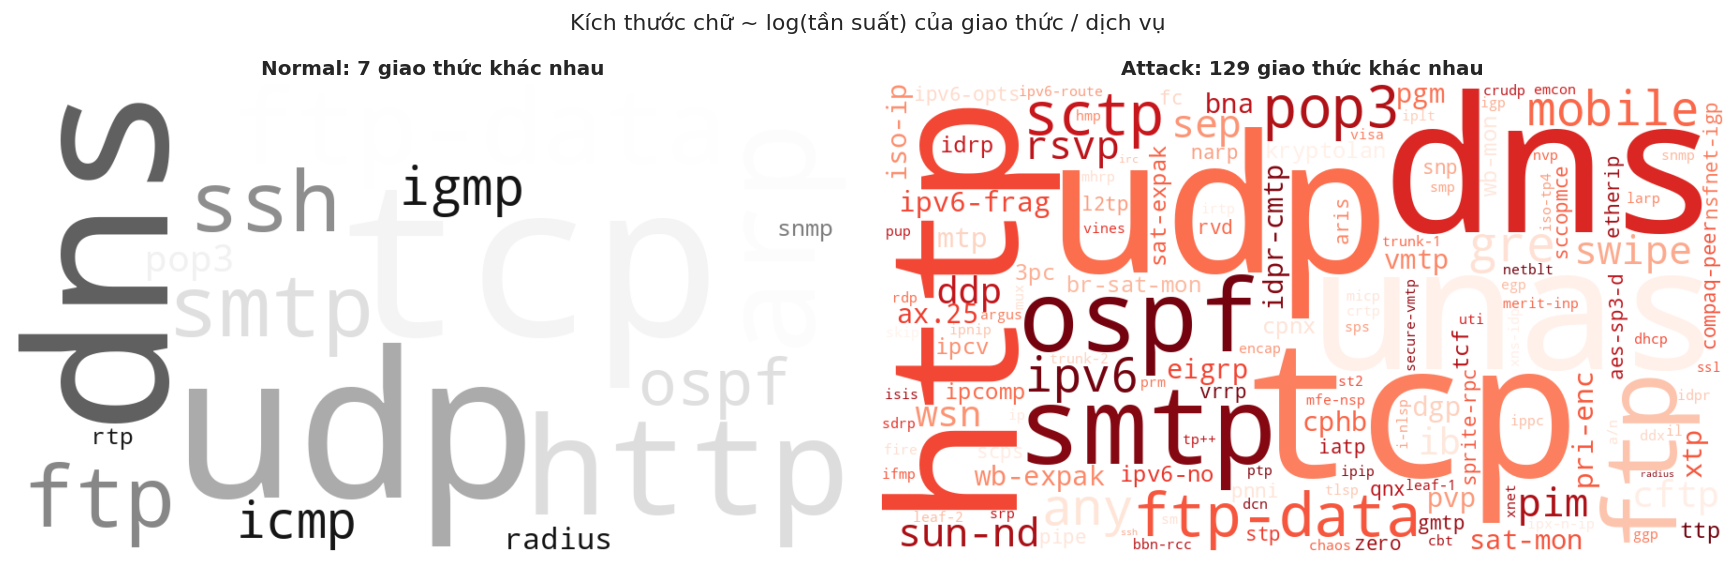

In [12]:
# WordCloud: "từ vựng" giao thức + dịch vụ của lưu lượng bình thường và tấn công
def vocab(df):
    freq = pd.concat([df['proto'], df['service'][df['service'] != 'unknown']]).value_counts()
    return np.log1p(freq).to_dict()          # log để giao thức hiếm vẫn nhìn thấy được

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, name, cmap in zip(axes, ['Normal', 'Attack'], ['Greys', 'Reds']):
    sub = train[train['label_name'] == name]
    wc = WordCloud(width=900, height=500, background_color='white', colormap=cmap, random_state=1,
                   min_font_size=8, relative_scaling=0.6).generate_from_frequencies(vocab(sub))
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off')
    ax.set_title(f'{name}: {sub["proto"].nunique()} giao thức khác nhau')
fig.suptitle('Kích thước chữ ~ log(tần suất) của giao thức / dịch vụ', y=1.02)
plt.tight_layout(); save('07_wordcloud'); plt.show()

**Nhận xét Q2.**
- **Giao thức hiếm là dấu hiệu tấn công gần như tuyệt đối.** Ngoài `tcp`, `udp`, `arp`, tập train có 29.253 luồng dùng các giao thức khác (`unas`, `ospf`, `sctp`, ...), trong đó chỉ **98 luồng là bình thường (0,3%)**. Phần lớn là DoS và Exploits. WordCloud cho thấy điều này rất rõ: bên Attack là một "đám mây" hơn một trăm giao thức lạ, bên Normal chỉ có vài từ.
- **`arp` thì ngược lại:** cả 2.859 luồng đều bình thường.
- **Generic gắn chặt với DNS:** 39.116/40.000 luồng Generic (97,8%) đi qua dịch vụ `dns` trên `udp`.
- **`ssh` gần như chỉ có lưu lượng bình thường** (1.291/1.302 luồng).
- **Trạng thái `INT`** (chỉ có gói một chiều, không được phản hồi) có 93% là tấn công; trạng thái `CON` có 92% là bình thường.

## Q3. Dấu hiệu định lượng nào phân biệt tấn công với bình thường?

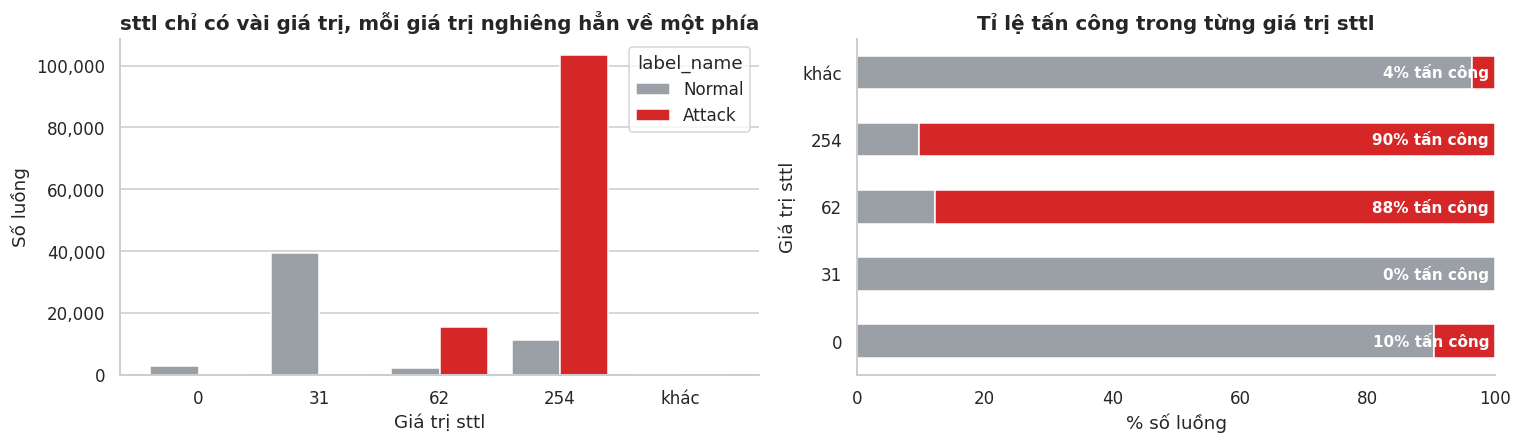

In [13]:
# sttl (Time-To-Live phía nguồn) chỉ nhận vài giá trị rời rạc -> vẽ cột theo từng giá trị
top_ttl = train['sttl'].value_counts().index[:4].sort_values()
ttl = train.assign(sttl_v=np.where(train['sttl'].isin(top_ttl), train['sttl'].astype(str), 'khác'))
ct = pd.crosstab(ttl['sttl_v'], ttl['label_name'])[['Normal', 'Attack']]
ct = ct.loc[[str(v) for v in top_ttl] + (['khác'] if 'khác' in ct.index else [])]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ct.plot(kind='bar', ax=axes[0], color=[BIN_PALETTE['Normal'], BIN_PALETTE['Attack']], width=0.8)
axes[0].set(xlabel='Giá trị sttl', ylabel='Số luồng', title='sttl chỉ có vài giá trị, mỗi giá trị nghiêng hẳn về một phía')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].grid(axis='x', visible=False); plt.setp(axes[0].get_xticklabels(), rotation=0)

pct = ct.div(ct.sum(axis=1), axis=0) * 100
pct.plot(kind='barh', stacked=True, ax=axes[1], color=[BIN_PALETTE['Normal'], BIN_PALETTE['Attack']], legend=False)
for y, v in enumerate(pct['Attack']):
    axes[1].text(99, y, f'{v:.0f}% tấn công', ha='right', va='center', color='white', fontsize=10, fontweight='bold')
axes[1].set(xlabel='% số luồng', ylabel='Giá trị sttl', xlim=(0, 100), title='Tỉ lệ tấn công trong từng giá trị sttl')
axes[1].grid(False)
plt.tight_layout(); save('08_sttl'); plt.show()

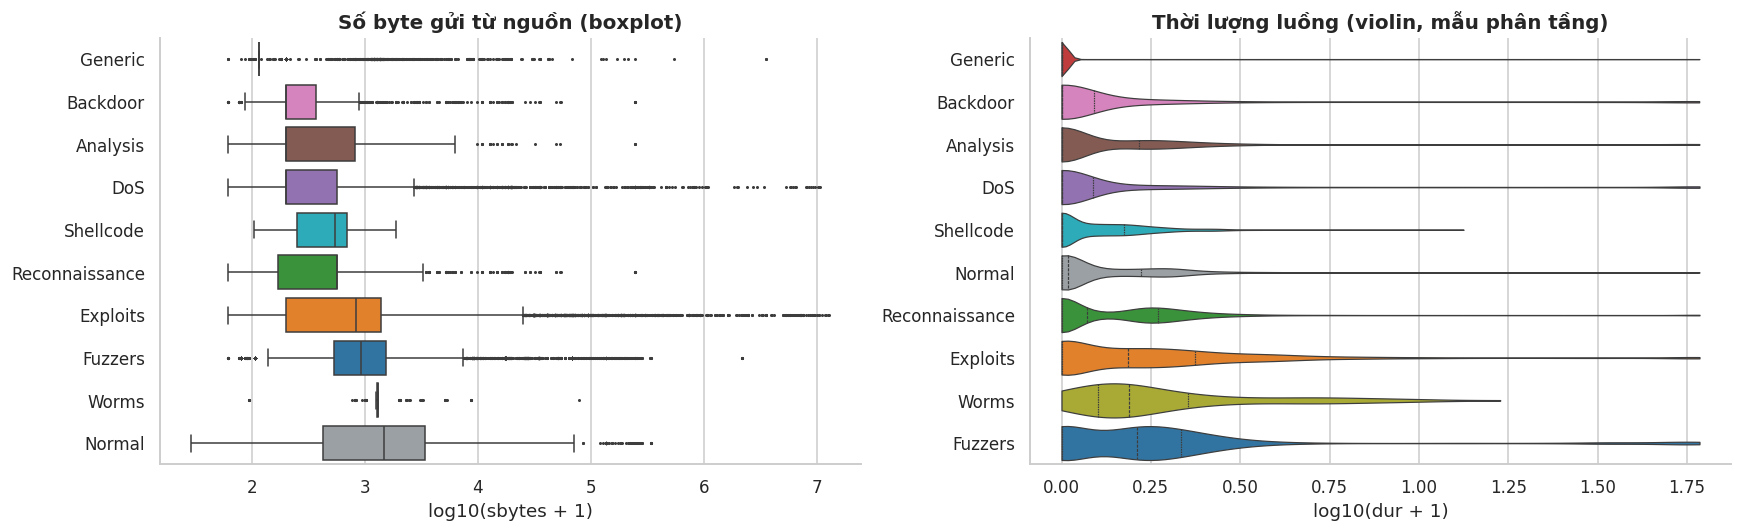

In [14]:
# Boxplot + violin trên thang log, sắp xếp theo trung vị
def by_median(col):
    return logd.groupby('attack_cat', observed=True)[col].median().sort_values().index.astype(str).tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
o = by_median('sbytes')
sns.boxplot(data=logd, x='sbytes', y='attack_cat', order=o, hue='attack_cat', palette=PALETTE,
            legend=False, fliersize=1, ax=axes[0])
axes[0].set(xlabel='log10(sbytes + 1)', ylabel='', title='Số byte gửi từ nguồn (boxplot)')

o = by_median('dur')
sns.violinplot(data=strat_sample(logd, 3000), x='dur', y='attack_cat', order=o, hue='attack_cat', palette=PALETTE,
               legend=False, density_norm='width', cut=0, inner='quartile', linewidth=0.8, ax=axes[1])
axes[1].set(xlabel='log10(dur + 1)', ylabel='', title='Thời lượng luồng (violin, mẫu phân tầng)')
plt.tight_layout(); save('09_box_violin'); plt.show()

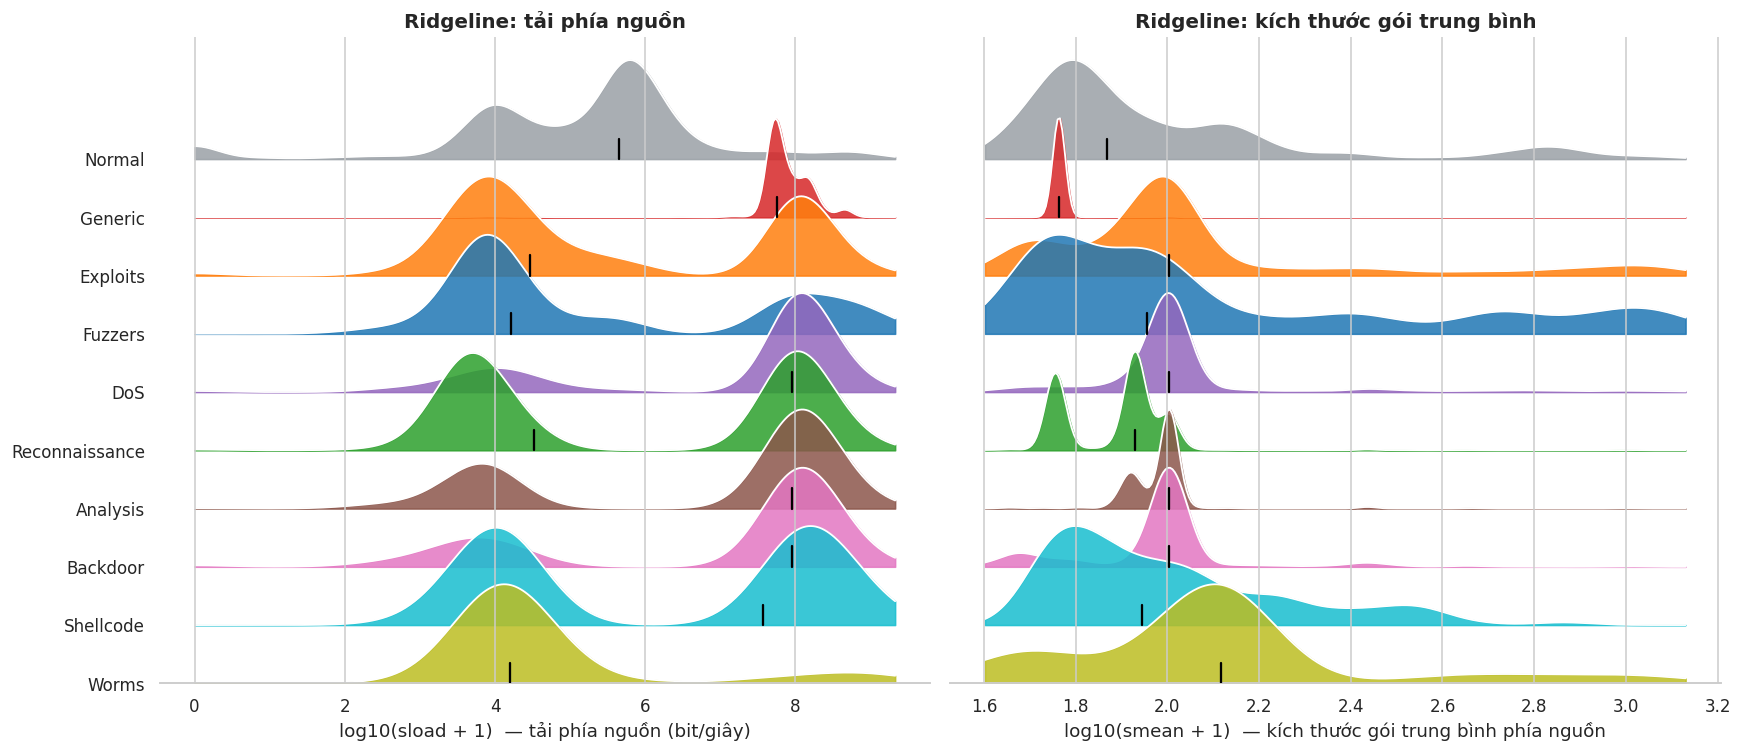

In [15]:
# Ridgeline: so sánh hình dạng phân phối của 10 loại trên cùng một trục
def ridgeline(data, col, ax, overlap=1.7, n=4000, xlabel=None):
    x = data[col]
    grid = np.linspace(x.quantile(0.001), x.quantile(0.999), 300)
    rng = np.random.default_rng(0)
    cats = ORDER[::-1]                                   # Normal nằm trên cùng
    for i, cat in enumerate(cats):
        v = x[data['attack_cat'] == cat]
        v = v.sample(min(len(v), n), random_state=0).to_numpy()
        v = v + rng.normal(0, 1e-3, len(v))              # nhiễu rất nhỏ để KDE không lỗi khi dữ liệu trùng nhau
        dens = gaussian_kde(v)(grid)
        dens = dens / dens.max() * overlap
        ax.fill_between(grid, i, i + dens, color=PALETTE[cat], alpha=0.85, zorder=-i)
        ax.plot(grid, i + dens, color='white', lw=1.2, zorder=-i)
        ax.plot([np.median(v)] * 2, [i, i + 0.35], color='black', lw=1.5, zorder=10)   # vạch trung vị
    ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats)
    ax.set(xlabel=xlabel or col, ylim=(0, len(cats) + overlap - 0.6))
    ax.grid(axis='y', visible=False); ax.spines['left'].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
ridgeline(logd, 'sload', axes[0], xlabel='log10(sload + 1)  — tải phía nguồn (bit/giây)')
axes[0].set_title('Ridgeline: tải phía nguồn')
ridgeline(logd, 'smean', axes[1], xlabel='log10(smean + 1)  — kích thước gói trung bình phía nguồn')
axes[1].set_title('Ridgeline: kích thước gói trung bình')
plt.tight_layout(); save('10_ridgeline'); plt.show()

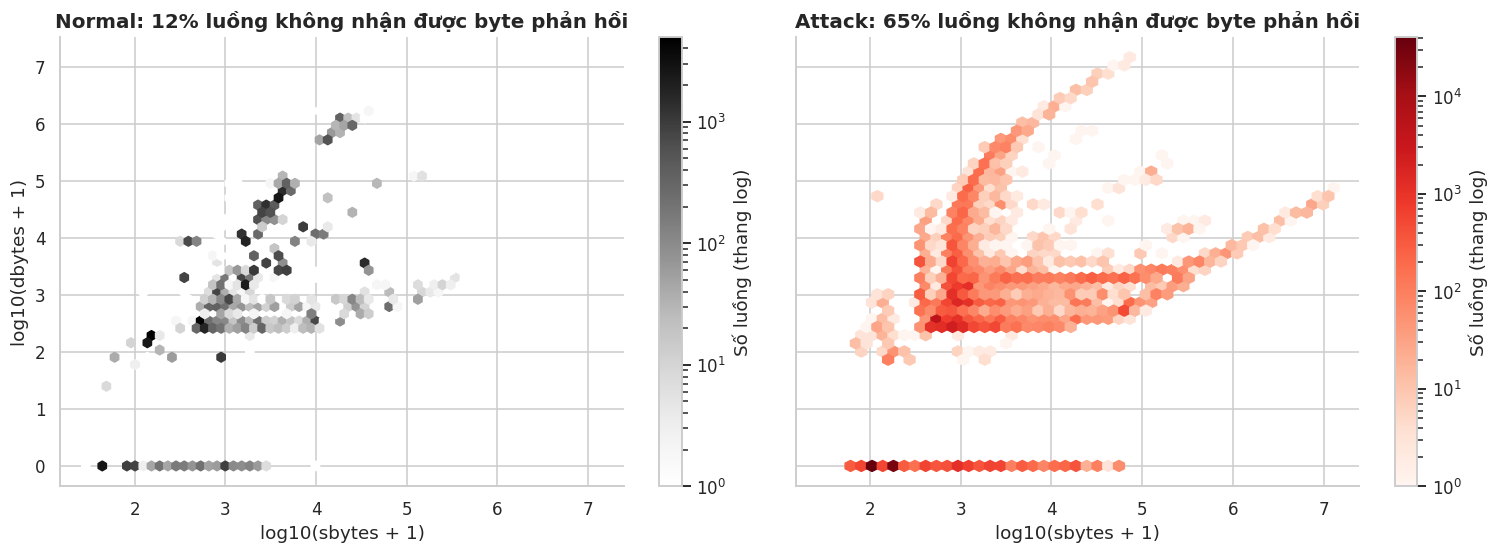

In [16]:
# Hexbin (biến thể của scatter cho dữ liệu lớn): byte gửi đi so với byte nhận về
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, name, cmap in zip(axes, ['Normal', 'Attack'], ['Greys', 'Reds']):
    sub = logd[logd['label_name'] == name]
    hb = ax.hexbin(sub['sbytes'], sub['dbytes'], gridsize=45, bins='log', cmap=cmap, mincnt=1)
    fig.colorbar(hb, ax=ax, label='Số luồng (thang log)')
    zero = (sub['dbytes'] == 0).mean() * 100
    ax.set(xlabel='log10(sbytes + 1)', title=f'{name}: {zero:.0f}% luồng không nhận được byte phản hồi')
axes[0].set_ylabel('log10(dbytes + 1)')
plt.tight_layout(); save('11_hexbin'); plt.show()

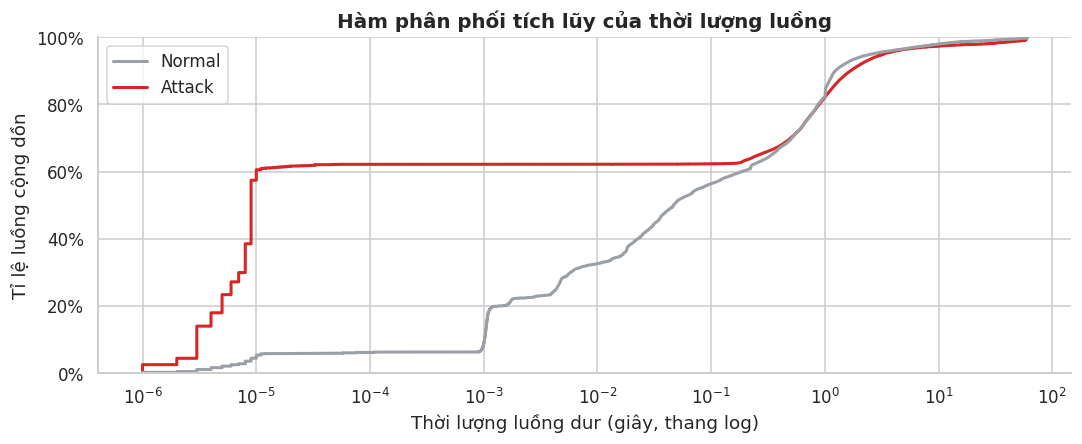

,Q1,Trung vị,Q3
label_name,,,
Attack,0.000006,0.000009,0.679699
Normal,0.001718,0.038602,0.639830


In [17]:
# ECDF: bao nhiêu % luồng kết thúc trong vòng x giây?
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.ecdfplot(data=train[train['dur'] > 0], x='dur', hue='label_name', palette=BIN_PALETTE,
             hue_order=['Normal', 'Attack'], log_scale=True, lw=2, ax=ax)
ax.set(xlabel='Thời lượng luồng dur (giây, thang log)', ylabel='Tỉ lệ luồng cộng dồn',
       title='Hàm phân phối tích lũy của thời lượng luồng')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.get_legend().set_title('')
plt.tight_layout(); save('12_ecdf'); plt.show()

q = train.groupby('label_name')['dur'].quantile([0.25, 0.5, 0.75]).unstack().round(6)
q.columns = ['Q1', 'Trung vị', 'Q3']; q

**Nhận xét Q3.**
- **`sttl` là đặc trưng phân biệt mạnh nhất.** 70% luồng bình thường có `sttl = 31`, và giá trị 31 không xuất hiện ở bất kỳ luồng tấn công nào. Ngược lại, 87% luồng tấn công có `sttl = 254` và 13% có `sttl = 62`.
- Hexbin cho thấy một dải ngang ở `dbytes = 0` rất đậm bên phía tấn công: nhiều luồng tấn công **gửi đi mà không nhận phản hồi** (khớp với trạng thái `INT` ở Q2), còn luồng bình thường trao đổi hai chiều.
- Con số cụ thể: **65% luồng tấn công có `dbytes = 0`**, so với 12% ở luồng bình thường.
- **Tấn công diễn ra cực nhanh.** ECDF cho thấy một nửa số luồng tấn công kéo dài không quá 9 micro-giây (trung vị 0,000009 s), trong khi trung vị của luồng bình thường là 0,039 s. 62% luồng tấn công kết thúc dưới 1 mili-giây, so với 13% ở luồng bình thường.
- **Ridgeline tải nguồn (`sload`) có hai đỉnh ở hầu hết các loại tấn công:** một đỉnh quanh 10⁴ bit/s và một đỉnh quanh 10⁸ bit/s, còn Normal nằm ở giữa (đỉnh chính gần 10⁶). Tức là tấn công hoặc rất "êm", hoặc dội rất mạnh, ít khi ở mức bình thường. Generic chỉ có một đỉnh hẹp gần 10⁸.
- **Ridgeline kích thước gói (`smean`) có các đỉnh nhọn bất thường:** Generic dồn vào đúng 57 byte; DoS, Analysis, Backdoor dồn vào đúng 100 byte. Lưu lượng do người dùng thật tạo ra (Normal) trải rộng hơn nhiều. Gói có kích thước giống hệt nhau là dấu hiệu của công cụ sinh tấn công tự động.

## Q4. "Chân dung" của từng loại tấn công

Để so sánh nhiều đặc trưng khác đơn vị, mỗi giá trị được đổi thành **hạng phần trăm** (percentile, 0–1) trong toàn bộ dữ liệu, rồi lấy trung bình theo từng loại. Giá trị 0,5 nghĩa là "ngang mức trung bình của toàn bộ lưu lượng".

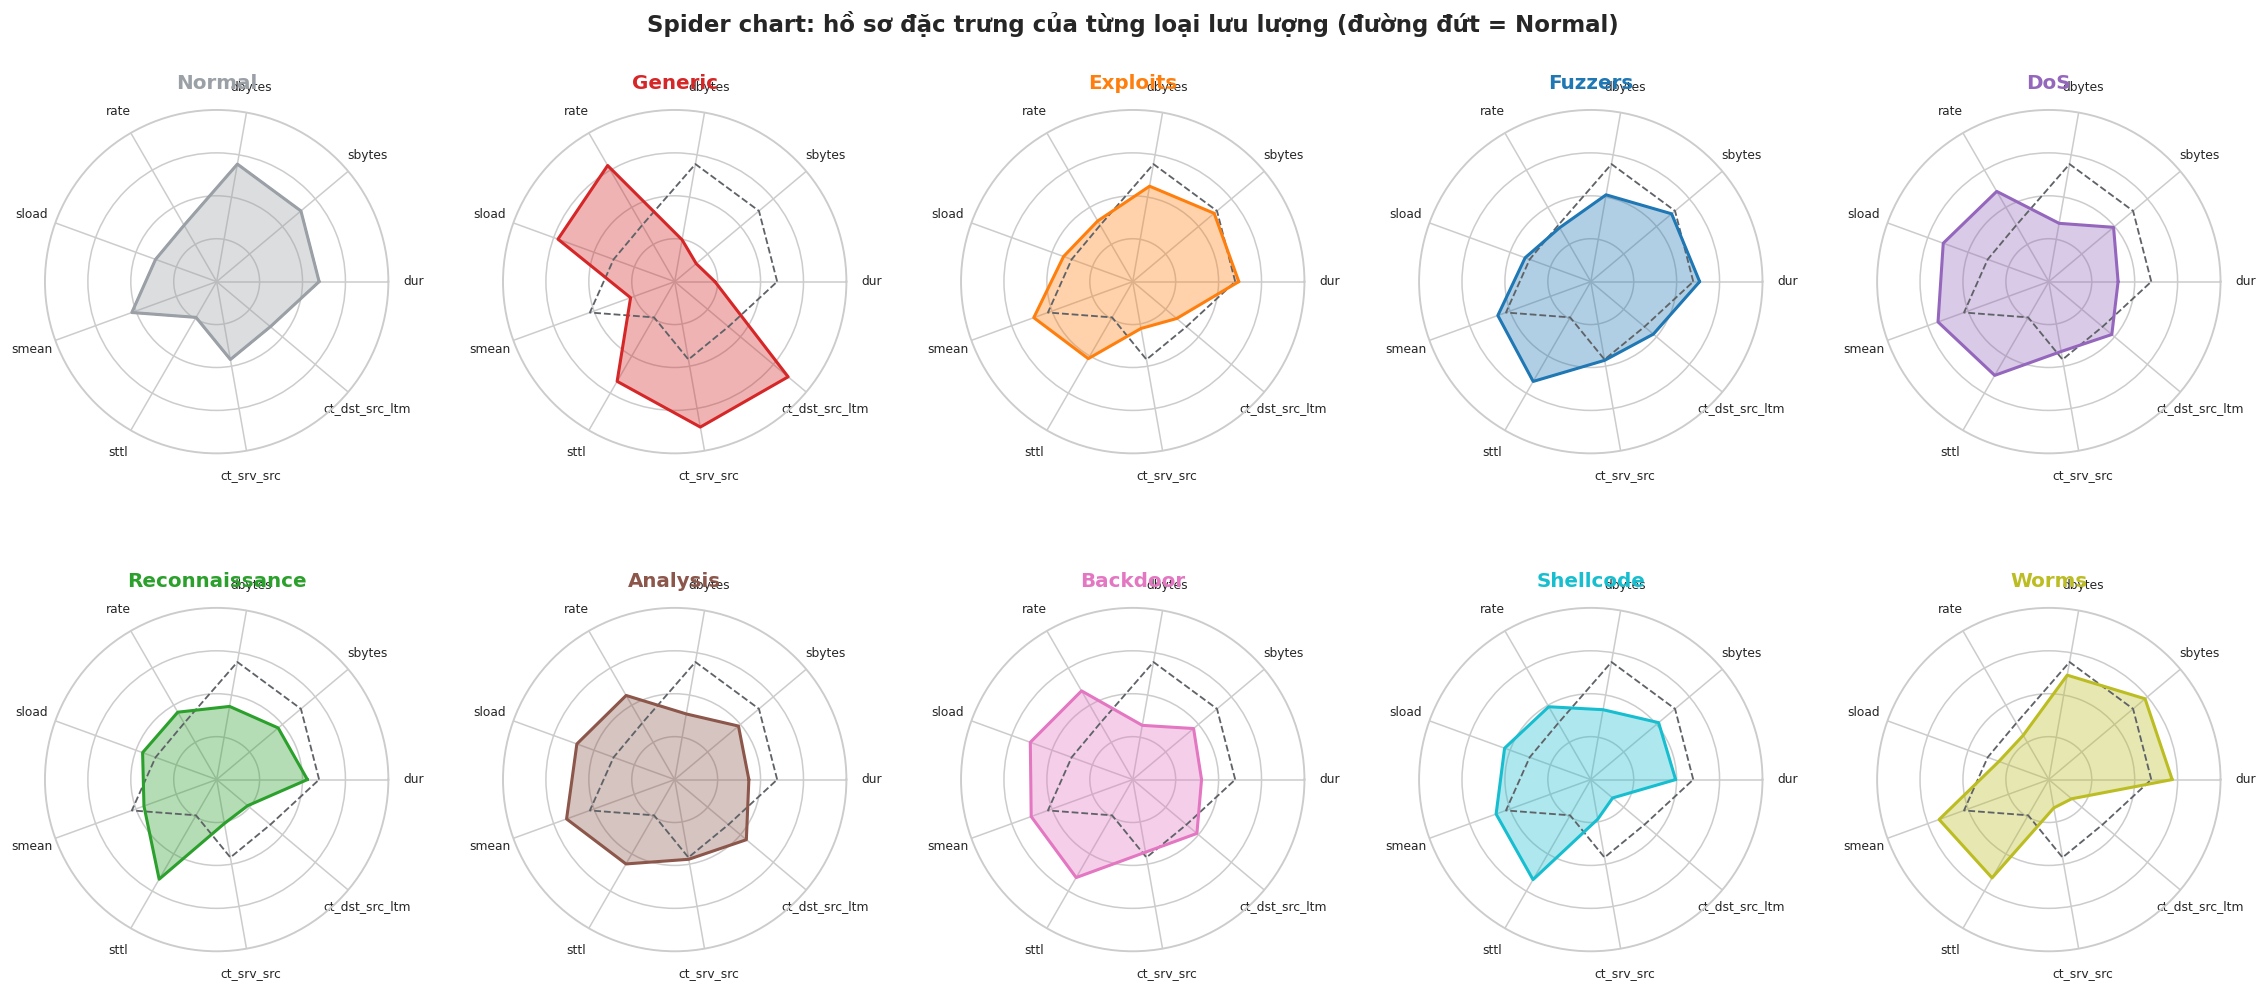

In [18]:
PROFILE = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'smean', 'dmean',
           'sttl', 'dttl', 'sinpkt', 'dinpkt', 'sjit', 'tcprtt', 'ct_srv_src', 'ct_dst_src_ltm',
           'ct_src_dport_ltm', 'ct_state_ttl']
profile = (train[PROFILE].rank(pct=True)
           .groupby(train['attack_cat'], observed=True).mean().reindex(ORDER))

RADAR = ['dur', 'sbytes', 'dbytes', 'rate', 'sload', 'smean', 'sttl', 'ct_srv_src', 'ct_dst_src_ltm']
angles = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist()
angles += angles[:1]
closed = lambda cat: profile.loc[cat, RADAR].tolist() + [profile.loc[cat, RADAR[0]]]

fig, axes = plt.subplots(2, 5, figsize=(21, 9), subplot_kw=dict(polar=True))
for ax, cat in zip(axes.ravel(), ORDER):
    ax.plot(angles, closed('Normal'), color='#5F6368', lw=1.2, ls='--', label='Normal (tham chiếu)')
    ax.plot(angles, closed(cat), color=PALETTE[cat], lw=2)
    ax.fill(angles, closed(cat), color=PALETTE[cat], alpha=0.35)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(RADAR, fontsize=8)
    ax.set_ylim(0, 1); ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels([])
    ax.set_title(cat, color=PALETTE[cat], pad=14)
fig.suptitle('Spider chart: hồ sơ đặc trưng của từng loại lưu lượng (đường đứt = Normal)', fontsize=15, fontweight='bold')
plt.tight_layout(); fig.subplots_adjust(hspace=0.45, top=0.88); save('13_spider'); plt.show()

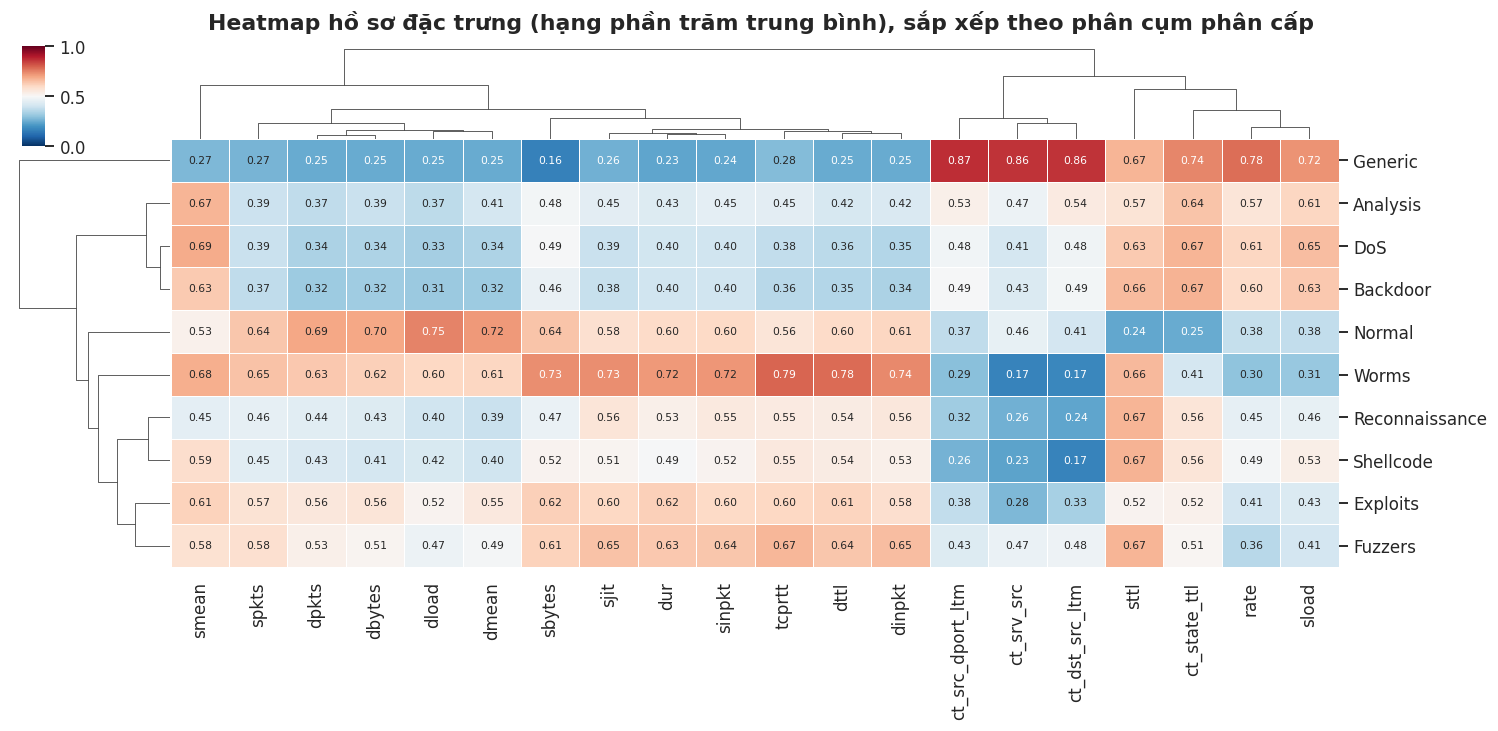

Khoảng cách trung bình tới hồ sơ Normal (càng lớn càng dễ phân biệt):
attack_cat
Generic           0.401
Backdoor          0.249
DoS               0.243
Analysis          0.212
Shellcode         0.178
Reconnaissance    0.160
Worms             0.147
Fuzzers           0.109
Exploits          0.093


In [19]:
# Clustermap: heatmap + phân cụm phân cấp -> loại tấn công nào giống nhau?
g = sns.clustermap(profile, cmap='RdBu_r', center=0.5, vmin=0, vmax=1, figsize=(14, 6.5),
                   linewidths=0.4, linecolor='white', annot=True, fmt='.2f', annot_kws={'fontsize': 7},
                   dendrogram_ratio=(0.12, 0.18), cbar_pos=(0.02, 0.83, 0.015, 0.14))
g.ax_heatmap.set(xlabel='', ylabel='')
g.fig.suptitle('Heatmap hồ sơ đặc trưng (hạng phần trăm trung bình), sắp xếp theo phân cụm phân cấp', y=1.02, fontweight='bold')
g.savefig('figures/14_clustermap.png', dpi=200, bbox_inches='tight'); plt.show()

far = (profile.loc[ATTACKS] - profile.loc['Normal']).abs().mean(axis=1).sort_values(ascending=False)
print('Khoảng cách trung bình tới hồ sơ Normal (càng lớn càng dễ phân biệt):')
print(far.round(3).to_string())

In [20]:
# Parallel coordinates (tương tác): mỗi đường là một luồng
pc = strat_sample(logd, 400)
dims = ['sttl', 'dur', 'sbytes', 'dbytes', 'rate', 'smean', 'ct_srv_src', 'ct_state_ttl']
fig = px.parallel_coordinates(pc, dimensions=dims, color='label',
                              color_continuous_scale=[[0, BIN_PALETTE['Normal']], [1, BIN_PALETTE['Attack']]],
                              title='Parallel coordinates (xám = Normal, đỏ = Attack) — kéo trên trục để lọc')
fig.update_layout(coloraxis_showscale=False, height=480)
fig.show()

**Nhận xét Q4.**
- **Generic có hình dạng riêng không lẫn được:** `ct_srv_src` và `ct_dst_src_ltm` rất cao (trung bình ≈ 25 kết nối lặp lại, so với ≈ 4–6 ở Normal) nhưng lượng byte gửi đi rất nhỏ (trung bình ≈ 400 byte, thấp nhất trong các loại). Đó là dấu vết của việc **bắn hàng loạt gói nhỏ, giống nhau, tới cùng một dịch vụ**.
- **Normal** nổi bật ở `dbytes` cao (nhận về nhiều dữ liệu) và `sttl` thấp.
- **Dendrogram chia tấn công thành các nhóm có hồ sơ gần như trùng nhau:** (Analysis – DoS – Backdoor), (Exploits – Fuzzers), (Reconnaissance – Shellcode). Generic đứng riêng một nhánh.
- **Khoảng cách tới hồ sơ Normal:** Generic xa nhất (0,40), còn Exploits (0,09) và Fuzzers (0,11) gần Normal nhất, tức là khó phân biệt với lưu lượng bình thường nhất.
- Hai điều trên là **dự báo cho Q8**: mô hình sẽ nhầm lẫn trong nội bộ từng nhóm, và sẽ nhầm Normal với Fuzzers / Exploits.

## Q5. Các đặc trưng liên quan với nhau như thế nào?

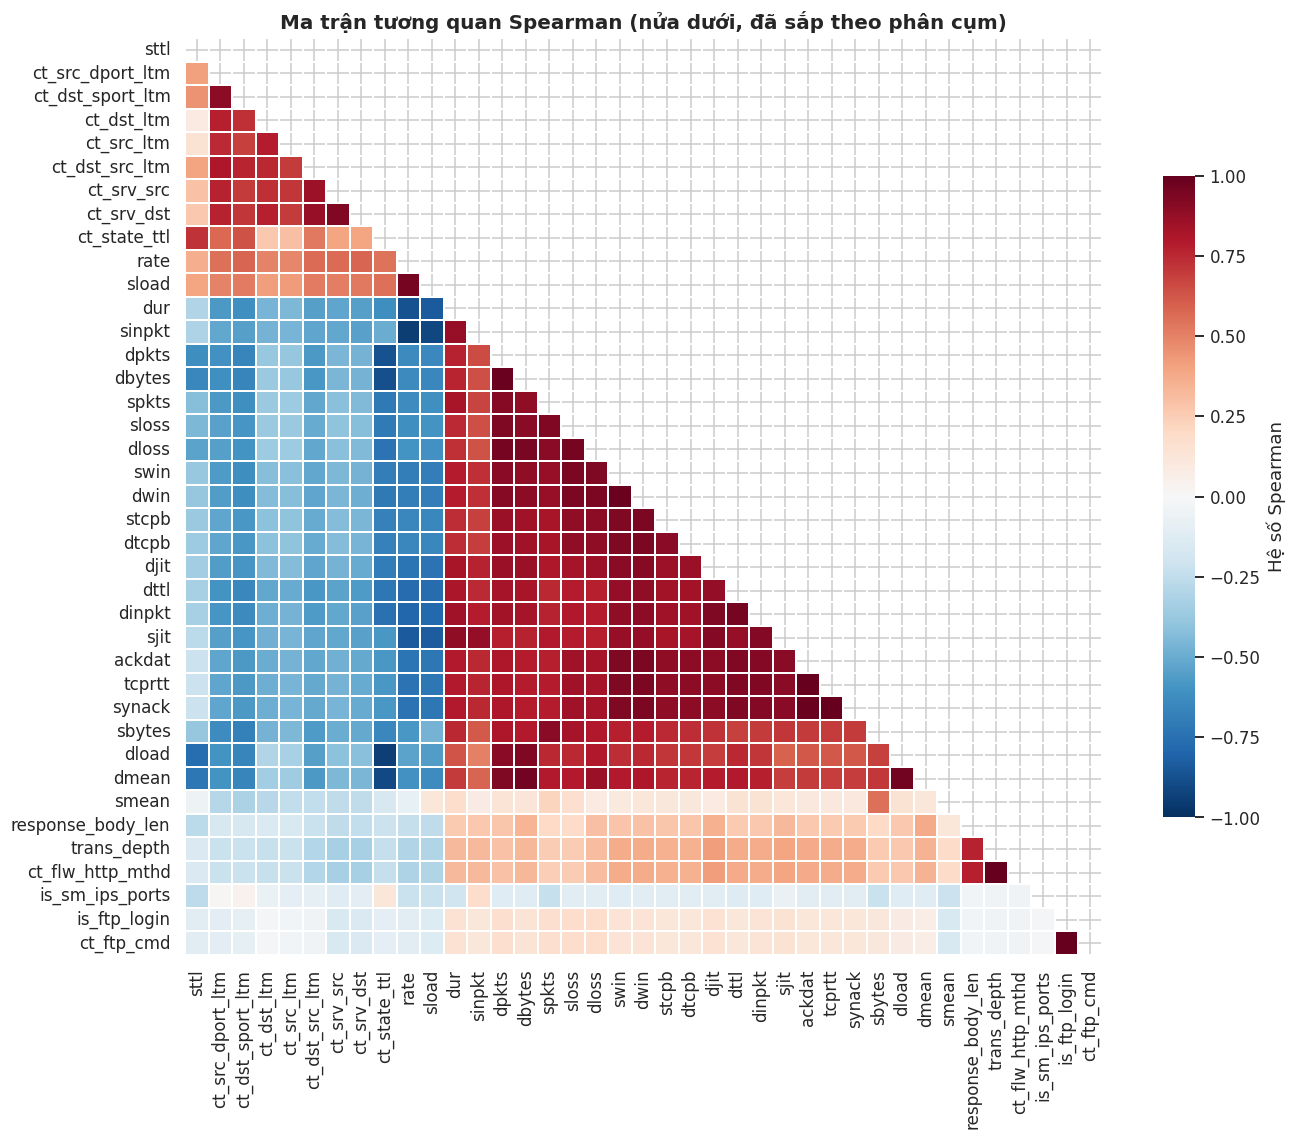

Có 56 cặp đặc trưng có |tương quan| > 0,9 (thông tin gần như trùng lặp).


In [21]:
corr = train[NUM_COLS + ['label']].sample(min(len(train), 30000), random_state=0).corr(method='spearman')
feat_corr = corr.drop(index='label', columns='label')

# Sắp xếp lại theo phân cụm để các khối đặc trưng tương quan nằm cạnh nhau
import scipy.cluster.hierarchy as sch
link = sch.linkage(feat_corr.fillna(0), method='average')
order = feat_corr.index[sch.leaves_list(link)]
feat_corr = feat_corr.loc[order, order]

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(feat_corr, mask=np.triu(np.ones_like(feat_corr, dtype=bool)), cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={'shrink': 0.7, 'label': 'Hệ số Spearman'}, ax=ax)
ax.set_title('Ma trận tương quan Spearman (nửa dưới, đã sắp theo phân cụm)')
plt.tight_layout(); save('15_corr'); plt.show()

pairs = feat_corr.where(np.tril(np.ones_like(feat_corr, dtype=bool), k=-1)).stack()
print(f'Có {(pairs.abs() > 0.9).sum()} cặp đặc trưng có |tương quan| > 0,9 (thông tin gần như trùng lặp).')

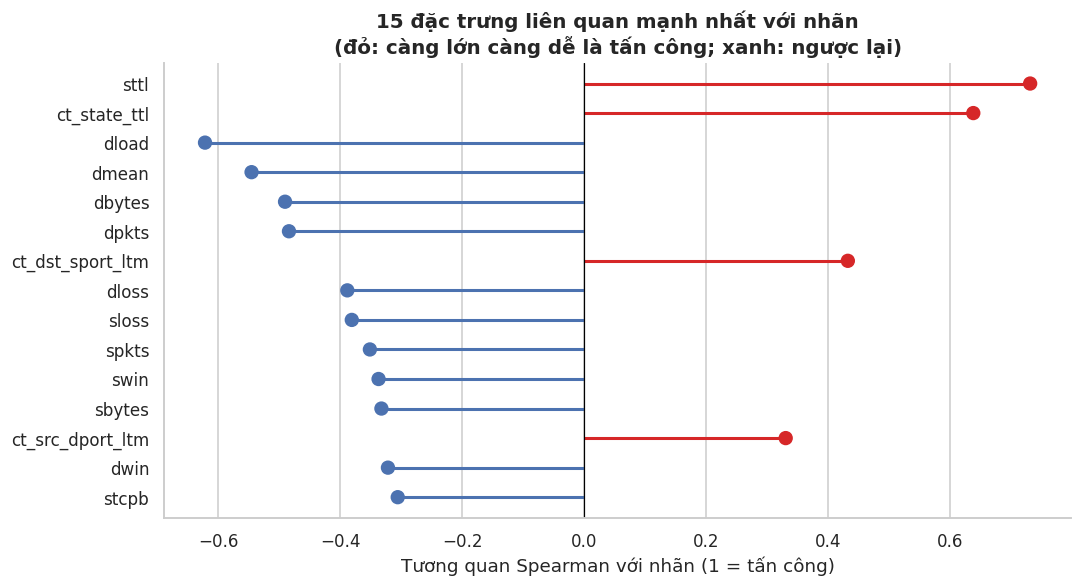

In [22]:
# Lollipop: đặc trưng nào tương quan mạnh nhất với nhãn tấn công?
lab = corr['label'].drop('label').dropna()
top = lab.reindex(lab.abs().sort_values(ascending=False).index[:15])[::-1]

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [BIN_PALETTE['Attack'] if v > 0 else '#4C72B0' for v in top]
ax.hlines(top.index, 0, top.values, color=colors, lw=2)
ax.scatter(top.values, top.index, color=colors, s=70, zorder=3)
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='Tương quan Spearman với nhãn (1 = tấn công)',
       title='15 đặc trưng liên quan mạnh nhất với nhãn\n(đỏ: càng lớn càng dễ là tấn công; xanh: ngược lại)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); save('16_lollipop'); plt.show()

**Nhận xét Q5.** Heatmap tương quan của bản cũ khó đọc vì giữ nguyên thứ tự cột và vẽ cả hai nửa. Ở đây chỉ vẽ nửa dưới, dùng bảng màu phân kỳ có tâm tại 0 và sắp xếp theo phân cụm, nên các **khối đặc trưng trùng thông tin** hiện ra thành các ô vuông đậm dọc đường chéo (nhóm khối lượng `spkts/sbytes/sloss`, nhóm bắt tay TCP `tcprtt/synack/ackdat`, nhóm đếm `ct_*`). Có 56 cặp đặc trưng có |tương quan| > 0,9.

Biểu đồ lollipop xác nhận bằng số điều đã thấy ở Q3: `sttl` (+0,73) và `ct_state_ttl` (+0,64) tương quan dương mạnh nhất với nhãn tấn công; còn nhóm đặc trưng **chiều phản hồi** `dload`, `dmean`, `dbytes`, `dpkts` (−0,62 đến −0,49) tương quan âm, tức là càng ít dữ liệu trả về thì càng dễ là tấn công.

## Q6. Cấu trúc phân cấp, mạng và luồng (chương 6)

In [23]:
# Treemap: Nhãn -> loại tấn công -> dịch vụ (diện tích = số luồng)
hier = (train.groupby(['label_name', 'attack_cat', 'service'], observed=True).size()
        .reset_index(name='n'))
hier['attack_cat'] = hier['attack_cat'].astype(str)
cmap = {**PALETTE, 'Attack': '#F2B8B5', '(?)': '#FFFFFF'}
fig = px.treemap(hier, path=[px.Constant('Toàn bộ lưu lượng'), 'label_name', 'attack_cat', 'service'], values='n',
                 color='attack_cat', color_discrete_map=cmap,
                 title='Treemap: Nhãn → Loại tấn công → Dịch vụ')
fig.update_traces(textinfo='label+percent parent', root_color='white')
fig.update_layout(height=600, margin=dict(t=50, l=5, r=5, b=5))
fig.show()

In [24]:
# Sunburst: cùng dữ liệu phân cấp nhưng nhìn theo giao thức
hier2 = (train.groupby(['proto_grp', 'attack_cat'], observed=True).size().reset_index(name='n'))
hier2['attack_cat'] = hier2['attack_cat'].astype(str)
fig = px.sunburst(hier2, path=['proto_grp', 'attack_cat'], values='n', color='attack_cat',
                  color_discrete_map=cmap, title='Sunburst: Giao thức → Loại tấn công')
fig.update_traces(textinfo='label+percent parent', insidetextorientation='radial')
fig.update_layout(height=600, margin=dict(t=50, l=5, r=5, b=5))
fig.show()

In [25]:
# Sankey: dòng chảy Giao thức -> Dịch vụ -> Trạng thái -> Loại tấn công
# Mỗi dải được tô theo loại tấn công nên có thể lần theo một loại qua cả 4 tầng.
sk = train.copy()
top_srv = sk['service'].value_counts().index[:6]
sk['service_grp'] = np.where(sk['service'].isin(top_srv), sk['service'], 'dịch vụ khác')
top_st = sk['state'].value_counts().index[:3]
sk['state_grp'] = np.where(sk['state'].isin(top_st), sk['state'], 'trạng thái khác')
STAGES = ['proto_grp', 'service_grp', 'state_grp', 'attack_cat']
MIN_FLOW = max(1, int(len(sk) * 0.001))          # bỏ dải < 0,1% để đỡ rối

labels, index = [], {}
def node(stage, value):
    key = (stage, str(value))
    if key not in index:
        index[key] = len(labels); labels.append(str(value))
    return index[key]

src, dst, val, col = [], [], [], []
for a, b in zip(STAGES[:-1], STAGES[1:]):
    keys = [a, b] if b == 'attack_cat' else [a, b, 'attack_cat']
    g = sk.groupby(keys, observed=True).size().reset_index(name='n')
    for _, r in g[g['n'] >= MIN_FLOW].iterrows():
        src.append(node(a, r[a])); dst.append(node(b, r[b])); val.append(int(r['n']))
        col.append(rgba(PALETTE[str(r['attack_cat'])], 0.45))

node_colors = [PALETTE.get(l, '#444444') for l in labels]
fig = go.Figure(go.Sankey(arrangement='snap',
    node=dict(label=labels, color=node_colors, pad=18, thickness=16, line=dict(color='white', width=0.5)),
    link=dict(source=src, target=dst, value=val, color=col)))
fig.update_layout(title='Sankey: Giao thức → Dịch vụ → Trạng thái → Loại tấn công', height=650, font_size=12)
fig.show()

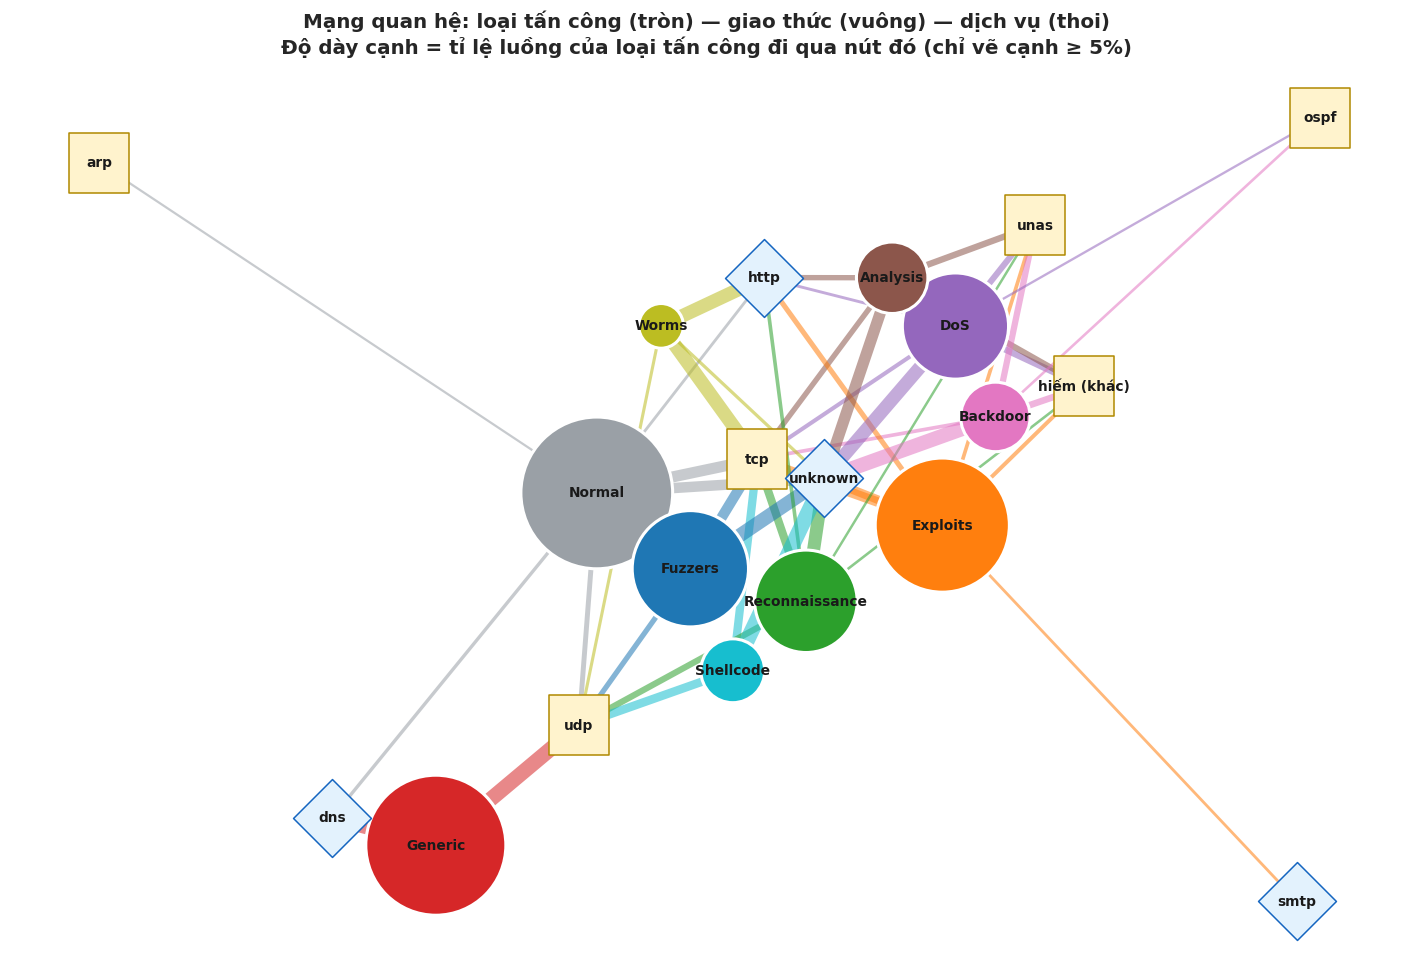

Nút trung tâm (được nhiều loại tấn công dùng chung):
tcp        9
unknown    9
http       6
udp        6
unas       5


In [26]:
# Network graph hai phía: loại tấn công <-> giao thức / dịch vụ mà nó sử dụng
G = nx.Graph()
for kind, colname in [('giao thức', 'proto_grp'), ('dịch vụ', 'service')]:
    ct = pd.crosstab(train['attack_cat'], train[colname], normalize='index')
    for cat in ORDER:
        for item, w in ct.loc[cat].items():
            if w >= 0.05:                               # chỉ nối khi >= 5% luồng của loại đó
                G.add_node(cat, kind='cat')
                G.add_node(f'{item}', kind=kind)
                G.add_edge(cat, f'{item}', weight=float(w))

pos = nx.spring_layout(G, weight='weight', k=0.9, seed=7, iterations=200)
cats = [n for n, d in G.nodes(data=True) if d['kind'] == 'cat']
protos = [n for n, d in G.nodes(data=True) if d['kind'] == 'giao thức']
servs = [n for n, d in G.nodes(data=True) if d['kind'] == 'dịch vụ']

fig, ax = plt.subplots(figsize=(13, 9))
for u, v, d in G.edges(data=True):
    c = u if u in cats else v
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], width=1 + 9 * d['weight'], edge_color=PALETTE[c], alpha=0.55, ax=ax)
size = train['attack_cat'].value_counts()
nx.draw_networkx_nodes(G, pos, nodelist=cats, node_color=[PALETTE[c] for c in cats],
                       node_size=[400 + 40 * np.sqrt(size[c]) for c in cats], edgecolors='white', linewidths=2, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=protos, node_shape='s', node_color='#FFF3CD', edgecolors='#B08900', node_size=1500, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=servs, node_shape='D', node_color='#E3F2FD', edgecolors='#1565C0', node_size=1300, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', ax=ax)
ax.set_title('Mạng quan hệ: loại tấn công (tròn) — giao thức (vuông) — dịch vụ (thoi)\n'
             'Độ dày cạnh = tỉ lệ luồng của loại tấn công đi qua nút đó (chỉ vẽ cạnh ≥ 5%)')
ax.axis('off'); plt.tight_layout(); save('17_network'); plt.show()

deg = pd.Series({n: G.degree(n) for n in protos + servs}).sort_values(ascending=False)
print('Nút trung tâm (được nhiều loại tấn công dùng chung):'); print(deg.head(5).to_string())

**Nhận xét Q6.**
- **Treemap / sunburst** cho thấy quan hệ cha–con: ô Generic gần như chỉ có một ô con `dns`; ô Normal chia cho nhiều dịch vụ.
- **Sankey** kể lại toàn bộ đường đi: dải đỏ (Generic) chạy thẳng `udp → dns → INT → Generic` gần như không rẽ nhánh; nhóm giao thức hiếm tách chủ yếu sang DoS và Exploits; dải xám (Normal) đi chủ yếu qua `tcp → FIN`.
- **Network graph** cho thấy `tcp`, `udp` và `unknown` là các nút trung tâm mà hầu hết loại tấn công dùng chung, nên một mình chúng không phân biệt được gì. Các nút nằm ở rìa (chỉ nối với một hai loại) mới là dấu hiệu nhận dạng.

*Ghi chú về dữ liệu không gian (chương 7):* tập dữ liệu này không có thông tin địa lý (bản training/testing-set đã bỏ địa chỉ IP, và IP trong bản gốc là IP giả lập trong phòng thí nghiệm), nên bản đồ choropleth không áp dụng được một cách trung thực.

## Q7. Trong không gian ít chiều, các loại tấn công có tách nhau không?

t-SNE chạy trong 76 giây trên 7,330 điểm


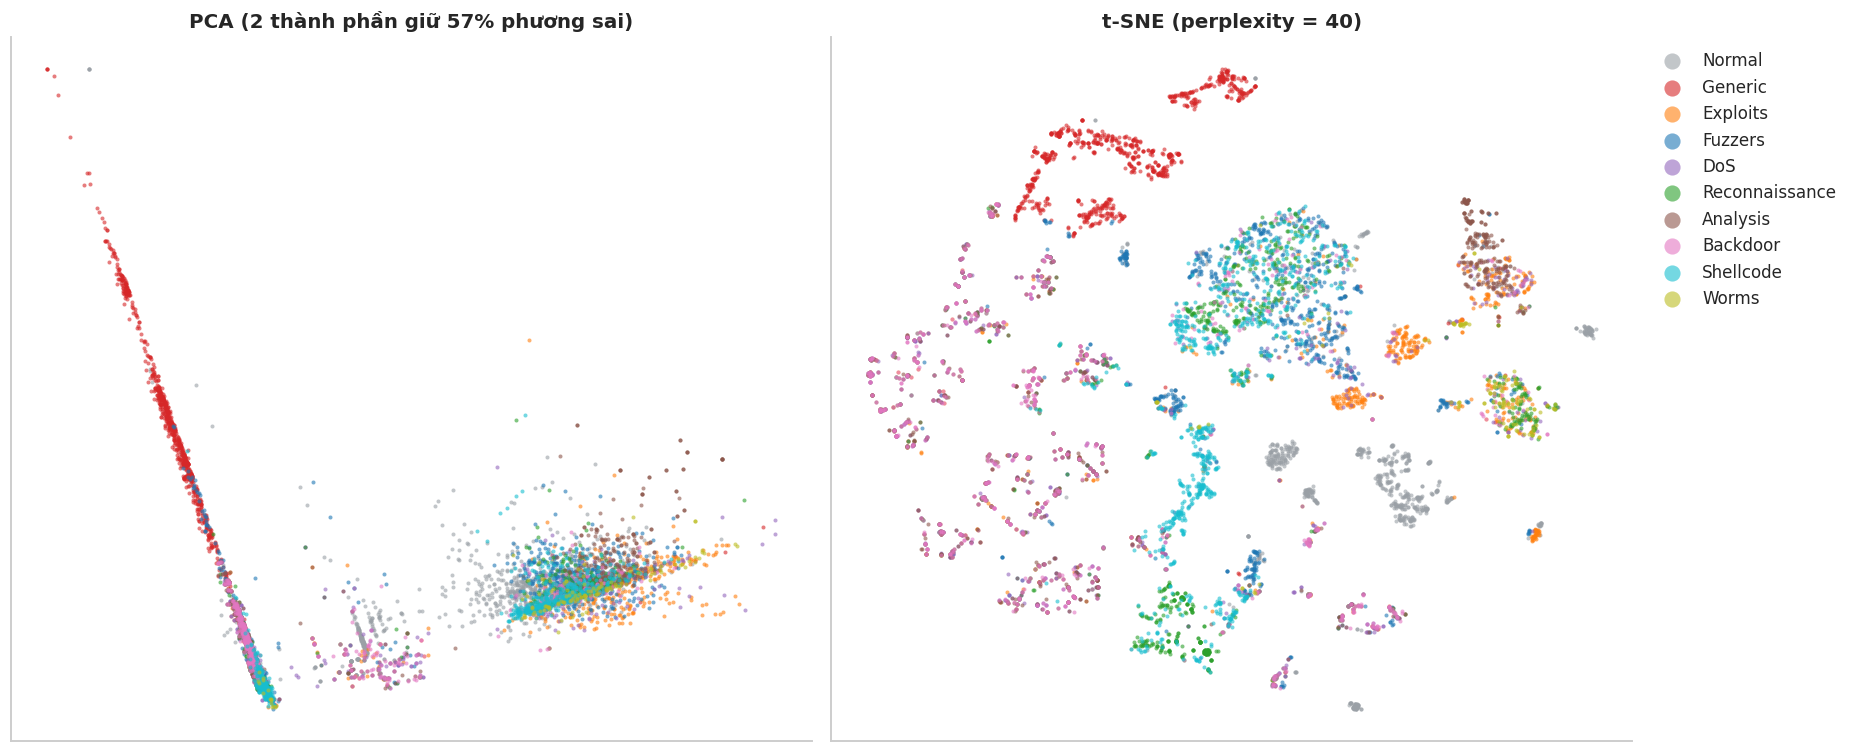

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

emb = strat_sample(logd, 800)
Xs = StandardScaler().fit_transform(emb[NUM_COLS])

pca = PCA(n_components=2, random_state=0)
p2 = pca.fit_transform(Xs)
t0 = time.time()
t2 = TSNE(n_components=2, perplexity=40, init='pca', random_state=0).fit_transform(Xs)
print(f't-SNE chạy trong {time.time() - t0:.0f} giây trên {len(emb):,} điểm')

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, Z, title in [(axes[0], p2, f'PCA (2 thành phần giữ {pca.explained_variance_ratio_.sum() * 100:.0f}% phương sai)'),
                     (axes[1], t2, 't-SNE (perplexity = 40)')]:
    for cat in ORDER:
        m = (emb['attack_cat'] == cat).to_numpy()
        ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.6, color=PALETTE[cat], label=cat, linewidths=0)
    ax.set(title=title, xticks=[], yticks=[]); ax.grid(False)
leg = axes[1].legend(markerscale=4, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); save('18_pca_tsne'); plt.show()

**Cách đọc.** PCA là phép chiếu tuyến tính, giữ cấu trúc toàn cục; t-SNE là phi tuyến, giữ quan hệ láng giềng. Trên t-SNE, khoảng cách giữa các cụm và kích thước cụm **không** mang ý nghĩa, chỉ nên đọc "điểm nào nằm chung cụm với điểm nào".

**Nhận xét Q7.**
- Hai thành phần PCA giữ 57% phương sai. Generic nằm trên một dải riêng, tách khỏi phần còn lại; các loại khác chồng lên nhau, tức là **không tách được bằng đường thẳng**.
- Trên t-SNE, **Generic** (đỏ) và **Normal** (xám) tạo thành các cụm riêng, sạch.
- **Backdoor, DoS, Analysis** nằm lẫn vào nhau trong cùng các cụm nhỏ rải rác; **Fuzzers, Shellcode, Reconnaissance** trộn lẫn trong khối lớn ở giữa. Đây đúng là các nhóm mà clustermap ở Q4 đã chỉ ra.

## Q8. Từ quan sát trực quan đến phát hiện tự động

### 8.1 Một luật rút ra từ một biểu đồ

Biểu đồ `sttl` ở Q3 gợi ý một luật cực đơn giản: **nếu `sttl` thuộc {62, 254, 255} thì báo tấn công.** Thử xem nó đúng đến đâu.

In [28]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)

def rule_sttl(df):
    return df['sttl'].isin([62, 254, 255]).astype(int)

rows = []
for name, d in [('Train', train), ('Test', test)]:
    pred = rule_sttl(d)
    rows.append({'Tập': name, 'Accuracy': accuracy_score(d['label'], pred), 'Precision': precision_score(d['label'], pred),
                 'Recall': recall_score(d['label'], pred), 'F1': f1_score(d['label'], pred)})
rule_res = pd.DataFrame(rows).set_index('Tập')
rule_res.round(4)

,Accuracy,Precision,Recall,F1
Tập,,,,
Train,0.9219,0.8988,0.9975,0.9456
Test,0.7663,0.7024,0.9986,0.8247


Trên tập **train**, luật một dòng này đạt Accuracy **92,2%** và bắt được 99,75% luồng tấn công. Nhưng sang tập **test**, Accuracy tụt xuống **76,6%**: vẫn bắt được 99,9% tấn công, song Precision chỉ còn 70%, vì ở tập test có nhiều luồng bình thường cũng mang các giá trị `sttl` này.

**Điều này nói lên hai việc:** (1) trực quan hóa tốt có thể tìm ra dấu hiệu phát hiện mà không cần mô hình; (2) dấu hiệu "đẹp" trên một tập dữ liệu chưa chắc đúng ở nơi khác. `sttl` phụ thuộc vào hệ điều hành / công cụ sinh lưu lượng trong phòng thí nghiệm, không phải bản chất của hành vi tấn công, nên một mô hình dựa vào `sttl` có thể chỉ đang học "máy nào phát ra gói".

### 8.2 Mô hình học máy, đánh giá trên tập test chính thức

Bản cũ có hai lỗi làm kết quả đẹp giả tạo, đã sửa ở đây:
1. Phần "chạy test set" gọi `train_and_evaluate(models, X_test, X_test, ...)`, tức là **huấn luyện trên tập test rồi chấm trên chính tập test** nên Random Forest ra 99,99%.
2. `LabelEncoder` được fit trước khi chia dữ liệu, và giá trị lạ ở tập test bị thay bằng lớp đầu tiên.

Ở đây: fit mọi thứ trên **train**, chỉ `transform`/`predict` trên **test**.

In [29]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

FEATS = NUM_COLS + CAT_COLS
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(train[CAT_COLS])

def to_X(df):
    X = df[FEATS].copy()
    X[CAT_COLS] = enc.transform(df[CAT_COLS])
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    return X

X_tr, y_tr = to_X(train), train['label']
X_te, y_te = to_X(test), test['label']

models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=0),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0),
}
try:
    from xgboost import XGBClassifier
    models['XGBoost'] = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method='hist', n_jobs=-1)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    models['HistGradientBoosting'] = HistGradientBoostingClassifier(random_state=0)

res, proba = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_tr, y_tr); t_fit = time.time() - t0
    p = m.predict_proba(X_te)[:, 1]; pred = (p >= 0.5).astype(int); proba[name] = p
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    res.append({'Mô hình': name, 'Accuracy': accuracy_score(y_te, pred), 'Precision': precision_score(y_te, pred),
                'Recall': recall_score(y_te, pred), 'F1': f1_score(y_te, pred), 'AUC': roc_auc_score(y_te, p),
                'Báo động giả (FPR)': fp / (fp + tn), 'Thời gian train (s)': t_fit})
    print(f'{name}: xong sau {t_fit:.1f}s')
res = pd.DataFrame(res).set_index('Mô hình')
res.round(4)

Naive Bayes: xong sau 0.2s
Logistic Regression: xong sau 6.3s
Decision Tree: xong sau 4.5s
Random Forest: xong sau 32.1s
XGBoost: xong sau 7.6s


,Accuracy,Precision,Recall,F1,AUC,Báo động giả (FPR),Thời gian train (s)
Mô hình,,,,,,,
Naive Bayes,0.6266,0.6290,0.7850,0.6984,0.7576,0.5674,0.1948
Logistic Regression,0.8117,0.7561,0.9714,0.8503,0.9325,0.3838,6.3355
Decision Tree,0.8675,0.8272,0.9598,0.8886,0.8961,0.2456,4.4703
Random Forest,0.8705,0.8164,0.9867,0.8935,0.9783,0.2719,32.1443
XGBoost,0.8747,0.8228,0.9846,0.8964,0.9840,0.2598,7.5624


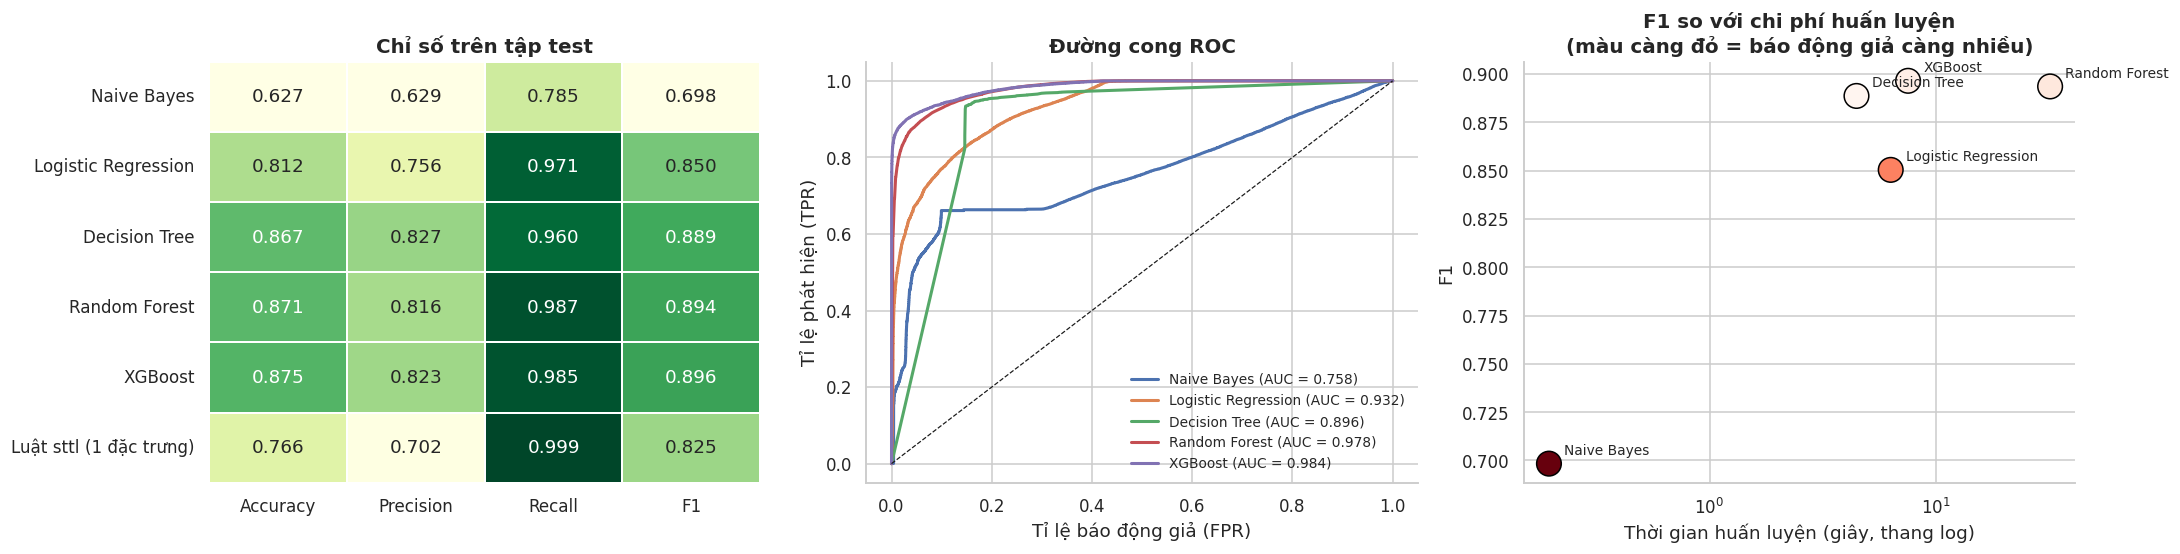

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))

# (a) Heatmap bảng chỉ số, có thêm dòng luật sttl để so sánh
tbl = res[['Accuracy', 'Precision', 'Recall', 'F1']].copy()
tbl.loc['Luật sttl (1 đặc trưng)'] = rule_res.loc['Test', ['Accuracy', 'Precision', 'Recall', 'F1']].values
sns.heatmap(tbl, annot=True, fmt='.3f', cmap='YlGn', vmin=0.7, vmax=1, linewidths=1, linecolor='white',
            cbar=False, ax=axes[0])
axes[0].set(title='Chỉ số trên tập test', ylabel='')

# (b) ROC
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[1].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {res.loc[name, "AUC"]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set(xlabel='Tỉ lệ báo động giả (FPR)', ylabel='Tỉ lệ phát hiện (TPR)', title='Đường cong ROC')
axes[1].legend(frameon=False, fontsize=9)

# (c) Đánh đổi chất lượng - chi phí
axes[2].scatter(res['Thời gian train (s)'], res['F1'], s=260, c=res['Báo động giả (FPR)'], cmap='Reds', edgecolors='black')
for name, r in res.iterrows():
    axes[2].annotate(name, (r['Thời gian train (s)'], r['F1']), textcoords='offset points', xytext=(10, 6), fontsize=9)
axes[2].set(xscale='log', xlabel='Thời gian huấn luyện (giây, thang log)', ylabel='F1',
            title='F1 so với chi phí huấn luyện\n(màu càng đỏ = báo động giả càng nhiều)')
axes[2].xaxis.set_minor_formatter(mtick.NullFormatter())
plt.tight_layout(); save('19_models'); plt.show()

### 8.3 Mô hình nhầm loại tấn công nào với loại nào?

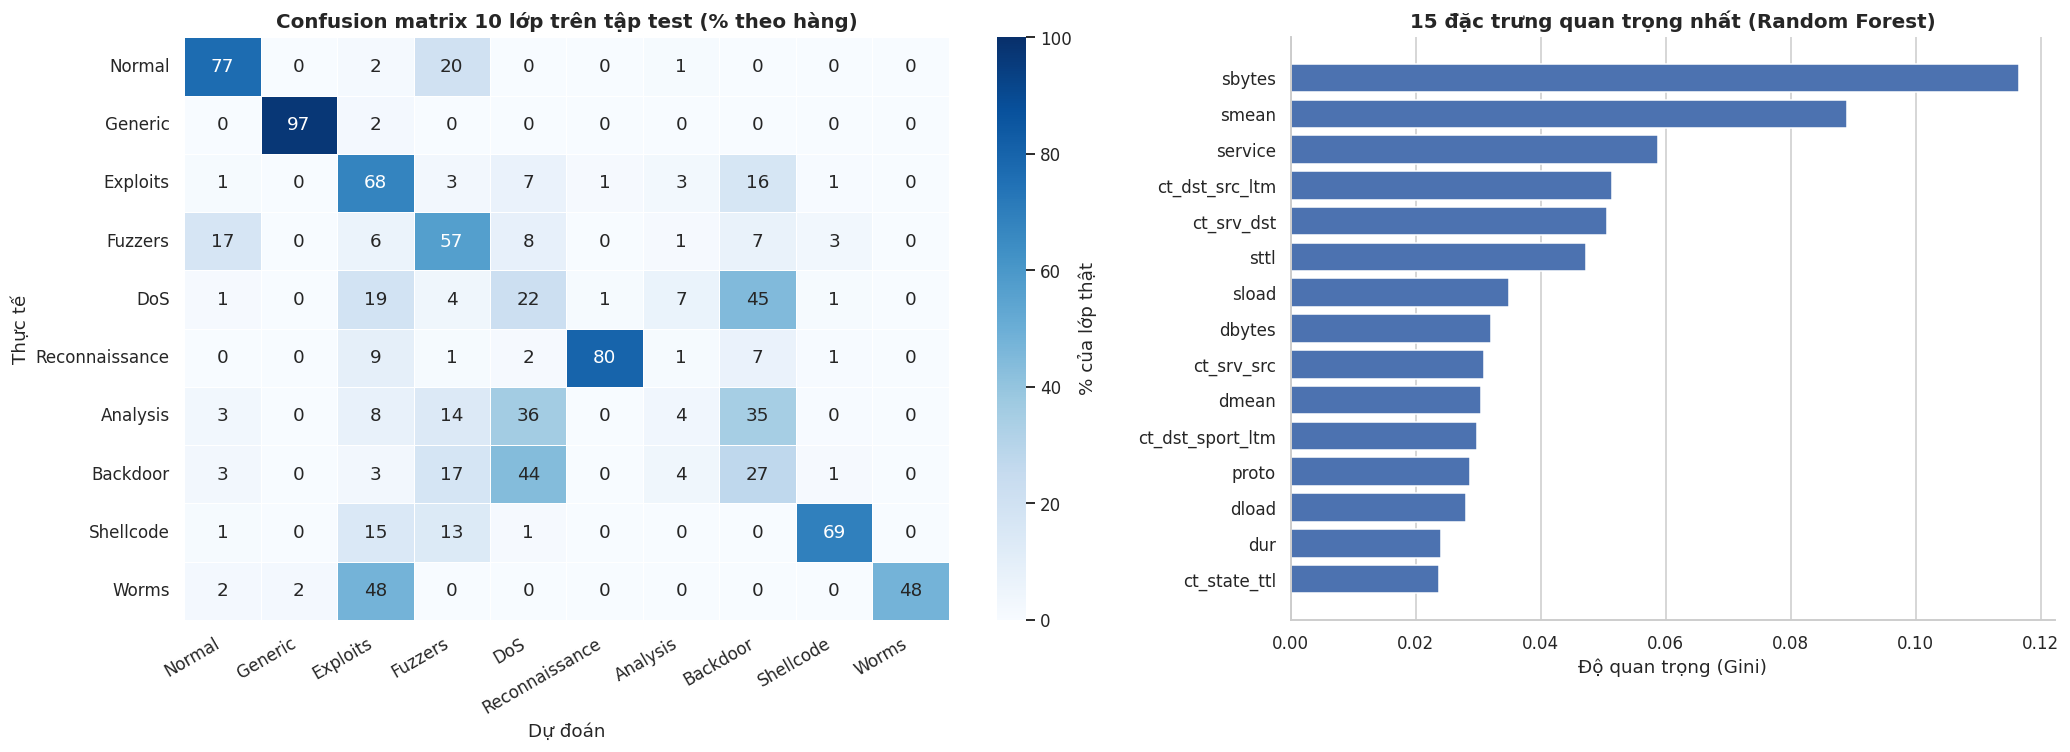

,precision,recall,f1-score,support
Normal,0.957,0.768,0.852,37000
Generic,0.999,0.970,0.984,18871
Exploits,0.734,0.678,0.705,11132
Fuzzers,0.295,0.568,0.388,6062
DoS,0.319,0.220,0.260,4089
Reconnaissance,0.931,0.797,0.859,3496
Analysis,0.024,0.035,0.028,677
Backdoor,0.034,0.273,0.060,583
Shellcode,0.345,0.693,0.460,378
Worms,0.677,0.477,0.560,44


In [31]:
best = RandomForestClassifier(n_estimators=150, n_jobs=-1, class_weight='balanced', random_state=0)
best.fit(X_tr, train['attack_cat'].astype(str))
pred_cat = best.predict(X_te)
true_cat = test['attack_cat'].astype(str)

cm = confusion_matrix(true_cat, pred_cat, labels=ORDER, normalize='true') * 100
fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(pd.DataFrame(cm, index=ORDER, columns=ORDER), annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100,
            linewidths=0.5, linecolor='white', cbar_kws={'label': '% của lớp thật'}, ax=axes[0])
axes[0].set(xlabel='Dự đoán', ylabel='Thực tế', title='Confusion matrix 10 lớp trên tập test (% theo hàng)')
plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right')

imp = pd.Series(best.feature_importances_, index=FEATS).sort_values().tail(15)
axes[1].barh(imp.index, imp.values, color='#4C72B0')
axes[1].set(xlabel='Độ quan trọng (Gini)', title='15 đặc trưng quan trọng nhất (Random Forest)')
axes[1].grid(axis='y', visible=False)
plt.tight_layout(); save('20_confusion_importance'); plt.show()

rep = pd.DataFrame(classification_report(true_cat, pred_cat, labels=ORDER, output_dict=True, zero_division=0)).T.loc[ORDER]
rep[['precision', 'recall', 'f1-score']].round(3).assign(support=rep['support'].astype(int))

**Nhận xét Q8.**
- **Kết quả nhị phân trên tập test chính thức:** XGBoost tốt nhất với Accuracy 87,5% và F1 0,896; Random Forest 87,1%; Decision Tree 86,7%; Logistic Regression 81,2%; Naive Bayes 62,7%. Các con số này thấp hơn rõ so với 93–96% khi tự chia 80/20 từ tập train ở bản cũ, và đây mới là con số trung thực vì tập test có phân bố khác (Q1).
- **Mô hình bắt gần hết tấn công nhưng báo động giả nhiều:** Recall của ba mô hình cây đạt 96–99% trong khi Precision chỉ 82–83%. Trong vận hành thực tế, báo động giả nhiều làm quản trị viên mệt mỏi và bỏ qua cảnh báo.
- **Luật `sttl` một đặc trưng đạt 76,6%**, thua mô hình tốt nhất khoảng 11 điểm phần trăm; phần hơn đó là giá trị mà 41 đặc trưng còn lại mang đến.
- **Confusion matrix 10 lớp khớp với dự báo từ biểu đồ:**
  - Generic được nhận đúng 97%, Shellcode 84%, Reconnaissance 83%: các loại có hồ sơ riêng rõ ràng.
  - **DoS chỉ được nhận đúng 17%**, 59% bị gán nhầm thành Backdoor; **Analysis chỉ 2%**, 65% bị gán thành Backdoor. Đó chính là nhánh (Analysis – DoS – Backdoor) trên clustermap ở Q4.
  - **30% luồng Normal bị gán nhầm thành Fuzzers**, đúng loại có hồ sơ gần Normal nhất ở Q4.
- **Đặc trưng quan trọng nhất** khi phân loại 10 lớp là `sbytes`, `smean`, `service`, `ct_dst_src_ltm`, `sttl`. `smean` đứng thứ hai là nhờ các đỉnh nhọn 57 byte và 100 byte đã thấy trên ridgeline (Q3).

**Trực quan hóa đã dự báo trước được điểm mạnh và điểm yếu của mô hình**, trước khi huấn luyện bất kỳ mô hình nào.

## Kết luận — kể chuyện bằng dữ liệu (chương 9)

**Thông điệp chính:** *Tấn công mạng để lại "dấu vân tay" nhìn thấy được bằng mắt, và mỗi loại có một dấu vân tay khác nhau.*

| Phát hiện | Biểu đồ chứng minh |
|---|---|
| 68% luồng là tấn công, nhưng 2 loại (Generic, Exploits) chiếm hơn 60% số tấn công; Worms chỉ có 130 luồng | Donut, bar, Pareto (Q1) |
| Giao thức hiếm ⇒ 99,7% là tấn công; `arp`, `ssh` ⇒ gần như luôn bình thường | Stacked bar, WordCloud (Q2) |
| Generic = bắn hàng loạt truy vấn DNS nhỏ qua UDP (97,8% qua `dns`) | Heatmap, Sankey, treemap (Q2, Q6) |
| `sttl = 31` chỉ có ở luồng bình thường; `sttl = 254` có ở 87% luồng tấn công | Bar theo giá trị (Q3) |
| Tấn công thường là một chiều: gửi đi, không có phản hồi (`dbytes = 0`, trạng thái `INT`) | Hexbin, stacked bar (Q2, Q3) |
| Mỗi loại tấn công có hồ sơ riêng; các loại giống nhau thì mô hình cũng nhầm | Spider, clustermap, t-SNE, confusion matrix (Q4, Q7, Q8) |
| Tấn công rất ngắn: một nửa số luồng tấn công kéo dài không quá 9 micro-giây | ECDF (Q3) |
| Luật 1 đặc trưng `sttl` đạt 92% trên train nhưng chỉ 77% trên test; mô hình tốt nhất (XGBoost) đạt 87,5% | Heatmap chỉ số, ROC (Q8) |
| DoS, Analysis, Backdoor gần như không phân biệt được với nhau (DoS chỉ được nhận đúng 17%) | Clustermap, t-SNE, confusion matrix (Q4, Q7, Q8) |

**Hạn chế.**
- Dữ liệu sinh trong phòng thí nghiệm: một số dấu hiệu (đặc biệt `sttl`) phản ánh cấu hình máy giả lập hơn là hành vi tấn công.
- Tỉ lệ tấn công 68% không phản ánh mạng thật.
- Không có thời gian và địa chỉ IP trong bản dữ liệu này nên không phân tích được diễn biến theo thời gian và theo không gian.

**Hướng phát triển.** Dùng bản UNSW-NB15 đầy đủ (có `stime`, `srcip`, `dstip`) để vẽ chuỗi thời gian và đồ thị mạng giữa các máy; triển khai dashboard theo dõi thời gian thực.